# Where Is The Leak?
### Machine Learning-Based Water Leakage Detection & Localization

**Graduation Project** - BattLeDIM 2018 dataset

This single notebook runs the whole pipeline. Run the cells from top to bottom.

- **Part 1 - Data Exploration:** loading, quality checks and exploratory analysis.
- **Part 2 - Preprocessing and Feature Engineering:** targets, features, blocked time-aware split and feature selection.
- **Part 3 - Modeling and Evaluation:** training, validation-based model selection, final test evaluation and saving.

# Part 1: Data Exploration

## 1. Importing Libraries

Only the libraries needed for data loading and exploration are imported here. Modeling libraries are imported in the notebooks where they are used.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("All libraries imported successfully!")

All libraries imported successfully!


## 2. Loading the Dataset

In this section, we load the three main CSV files of the BattLeDIM dataset:

- **Leakages:** Contains information about leakage events.
- **SCADA Flows:** Contains water flow measurements.
- **SCADA Pressures:** Contains pressure measurements.

We will inspect the structure and dimensions of each dataset before starting the analysis.

In [2]:
# Locate the dataset folder (works whether the notebook sits in the project root or in a sub-folder)
PROJECT_DIR = Path.cwd().parent
DATA_DIR = next(
    (p for p in [Path.cwd() / "Dataset", PROJECT_DIR / "Dataset"] if p.exists()),
    None
)
if DATA_DIR is None:
    raise FileNotFoundError(
        "Dataset folder not found. Expected a 'Dataset' folder next to this notebook "
        "or in its parent folder."
    )

# All three files use ';' as separator and ',' as decimal mark
READ_KW = dict(sep=";", decimal=",", parse_dates=["Timestamp"])

leakages = pd.read_csv(DATA_DIR / "2018_Leakages.csv", **READ_KW)
flows = pd.read_csv(DATA_DIR / "2018_SCADA_Flows.csv", **READ_KW)
pressures = pd.read_csv(DATA_DIR / "2018_SCADA_Pressures.csv", **READ_KW)

# Leakage values only (one column per pipe), kept separate from the timestamps
leakage_data = leakages.drop(columns="Timestamp")

print("All datasets loaded successfully from:", DATA_DIR)

All datasets loaded successfully from: c:\Users\dell\Desktop\Next Gen\Dataset


In [3]:
# Inspect the raw leakage file

file_path = DATA_DIR / "2018_Leakages.csv"

with open(file_path, "r", encoding="utf-8-sig") as file:
    for i in range(10):
        print(file.readline().rstrip())

Timestamp;p31;p158;p183;p232;p257;p369;p427;p461;p538;p628;p654;p673;p810;p866
2018-01-01 00:00:00;0;0;0;0;0;0;0;0;0;0;0;0;0;0
2018-01-01 00:05:00;0;0;0;0;0;0;0;0;0;0;0;0;0;0
2018-01-01 00:10:00;0;0;0;0;0;0;0;0;0;0;0;0;0;0
2018-01-01 00:15:00;0;0;0;0;0;0;0;0;0;0;0;0;0;0
2018-01-01 00:20:00;0;0;0;0;0;0;0;0;0;0;0;0;0;0
2018-01-01 00:25:00;0;0;0;0;0;0;0;0;0;0;0;0;0;0
2018-01-01 00:30:00;0;0;0;0;0;0;0;0;0;0;0;0;0;0
2018-01-01 00:35:00;0;0;0;0;0;0;0;0;0;0;0;0;0;0
2018-01-01 00:40:00;0;0;0;0;0;0;0;0;0;0;0;0;0;0


## 3. Dataset Overview

In this section, we explore the dimensions of the loaded datasets to understand their size and structure.

We will examine the number of rows and columns in each dataset.

In [4]:
# Display Dataset Dimensions

print("Leakages Dataset:")
print("Rows:", leakages.shape[0])
print("Columns:", leakages.shape[1])

print("\nFlows Dataset:")
print("Rows:", flows.shape[0])
print("Columns:", flows.shape[1])

print("\nPressures Dataset:")
print("Rows:", pressures.shape[0])
print("Columns:", pressures.shape[1])

Leakages Dataset:
Rows: 105120
Columns: 15

Flows Dataset:
Rows: 105120
Columns: 4

Pressures Dataset:
Rows: 105120
Columns: 34


In [5]:
# Display Column Names

print("Leakages Columns:")
print(leakages.columns.tolist())

print("\nFlows Columns:")
print(flows.columns.tolist())

print("\nPressures Columns:")
print(pressures.columns.tolist())

Leakages Columns:
['Timestamp', 'p31', 'p158', 'p183', 'p232', 'p257', 'p369', 'p427', 'p461', 'p538', 'p628', 'p654', 'p673', 'p810', 'p866']

Flows Columns:
['Timestamp', 'p227', 'p235', 'PUMP_1']

Pressures Columns:
['Timestamp', 'n1', 'n4', 'n31', 'n54', 'n105', 'n114', 'n163', 'n188', 'n215', 'n229', 'n288', 'n296', 'n332', 'n342', 'n410', 'n415', 'n429', 'n458', 'n469', 'n495', 'n506', 'n516', 'n519', 'n549', 'n613', 'n636', 'n644', 'n679', 'n722', 'n726', 'n740', 'n752', 'n769']


In [6]:
# Display First 5 Rows

print("Leakages Dataset:")
display(leakages.head())

print("Flows Dataset:")
display(flows.head())

print("Pressures Dataset:")
display(pressures.head())

Leakages Dataset:


,Timestamp,p31,p158,p183,p232,p257,p369,p427,p461,p538,p628,p654,p673,p810,p866
0,2018-01-01 00:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2018-01-01 00:05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2018-01-01 00:10:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2018-01-01 00:15:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2018-01-01 00:20:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Flows Dataset:


,Timestamp,p227,p235,PUMP_1
0,2018-01-01 00:00:00,77.77,83.93,44.04
1,2018-01-01 00:05:00,72.51,76.34,44.06
2,2018-01-01 00:10:00,71.54,78.68,44.06
3,2018-01-01 00:15:00,69.85,75.50,44.07
4,2018-01-01 00:20:00,77.12,82.99,44.03


Pressures Dataset:


,Timestamp,n1,n4,n31,n54,n105,n114,n163,n188,n215,...,n549,n613,n636,n644,n679,n722,n726,n740,n752,n769
0,2018-01-01 00:00:00,28.92,33.87,37.13,37.13,50.52,53.99,52.56,55.32,39.09,...,54.80,56.16,45.53,47.62,47.33,46.14,47.12,43.81,49.17,48.50
1,2018-01-01 00:05:00,28.94,33.89,37.16,37.23,50.60,54.09,52.67,55.42,39.10,...,54.90,56.26,45.61,47.71,47.39,46.19,47.17,43.83,49.22,48.54
2,2018-01-01 00:10:00,28.96,33.91,37.18,37.21,50.57,54.05,52.64,55.39,39.09,...,54.87,56.24,45.61,47.71,47.41,46.20,47.19,43.84,49.24,48.56
3,2018-01-01 00:15:00,28.98,33.93,37.19,37.27,50.60,54.08,52.70,55.45,39.09,...,54.92,56.30,45.65,47.75,47.43,46.21,47.21,43.84,49.26,48.57
4,2018-01-01 00:20:00,28.98,33.93,37.19,37.14,50.53,54.00,52.57,55.32,39.09,...,54.80,56.17,45.54,47.64,47.34,46.15,47.13,43.81,49.17,48.50


In [7]:
print("Flows Data Types:")
print(flows.dtypes)

print("\nPressures Data Types:")
print(pressures.dtypes)

Flows Data Types:
Timestamp    datetime64[ns]
p227                float64
p235                float64
PUMP_1              float64
dtype: object

Pressures Data Types:
Timestamp    datetime64[ns]
n1                  float64
n4                  float64
n31                 float64
n54                 float64
n105                float64
n114                float64
n163                float64
n188                float64
n215                float64
n229                float64
n288                float64
n296                float64
n332                float64
n342                float64
n410                float64
n415                float64
n429                float64
n458                float64
n469                float64
n495                float64
n506                float64
n516                float64
n519                float64
n549                float64
n613                float64
n636                float64
n644                float64
n679                float64
n722                f

In [8]:
# Statistical Summary of Flow Measurements

print("Flows Statistical Summary:")
display(flows.describe())

# Statistical Summary of Pressure Measurements

print("Pressures Statistical Summary:")
display(pressures.describe())

# Statistical Summary of Leakage Data

print("Leakages Statistical Summary:")
display(leakages.describe())

Flows Statistical Summary:


,Timestamp,p227,p235,PUMP_1
count,105120,105120.000000,105120.000000,105120.000000
mean,2018-07-02 11:57:29.999999744,98.200478,103.496288,26.838853
min,2018-01-01 00:00:00,15.930000,17.170000,0.000000
25%,2018-04-02 05:58:45,78.380000,83.440000,0.000000
50%,2018-07-02 11:57:30,104.930000,110.060000,43.910000
75%,2018-10-01 17:56:15,121.150000,126.292500,44.020000
max,2018-12-31 23:55:00,166.440000,195.280000,44.400000
std,NaN,29.967830,31.230732,21.457418


Pressures Statistical Summary:


,Timestamp,n1,n4,n31,n54,n105,n114,n163,n188,n215,...,n549,n613,n636,n644,n679,n722,n726,n740,n752,n769
count,105120,105120.000000,105120.000000,105120.000000,105120.000000,105120.000000,105120.000000,105120.000000,105120.000000,105120.000000,...,105120.000000,105120.00000,105120.000000,105120.000000,105120.000000,105120.000000,105120.000000,105120.000000,105120.000000,105120.000000
mean,2018-07-02 11:57:29.999999744,28.177514,33.264552,36.604953,36.796791,50.243409,53.659096,52.139037,54.889171,39.081582,...,54.434237,55.71263,45.175782,47.199625,46.959453,45.846231,46.751814,43.662465,48.783453,48.219050
min,2018-01-01 00:00:00,25.670000,30.900000,34.590000,34.330000,48.770000,51.970000,49.770000,52.480000,38.890000,...,52.400000,53.23000,43.520000,45.450000,45.570000,44.760000,45.370000,43.130000,47.310000,47.180000
25%,2018-04-02 05:58:45,27.740000,32.840000,36.190000,36.190000,49.990000,53.370000,51.680000,54.450000,39.080000,...,54.080000,55.25000,44.800000,46.790000,46.610000,45.580000,46.430000,43.530000,48.450000,47.970000
50%,2018-07-02 11:57:30,28.100000,33.200000,36.550000,36.810000,50.210000,53.620000,52.100000,54.850000,39.090000,...,54.390000,55.68000,45.140000,47.160000,46.910000,45.810000,46.700000,43.640000,48.740000,48.180000
75%,2018-10-01 17:56:15,28.630000,33.720000,37.030000,37.370000,50.520000,53.980000,52.610000,55.360000,39.090000,...,54.810000,56.20000,45.560000,47.630000,47.320000,46.120000,47.090000,43.800000,49.130000,48.480000
max,2018-12-31 23:55:00,29.360000,34.310000,37.570000,38.290000,50.950000,54.490000,53.350000,56.080000,39.100000,...,55.410000,56.96000,46.180000,48.300000,47.870000,46.530000,47.600000,44.000000,49.660000,48.870000
std,NaN,0.548432,0.541586,0.508478,0.739204,0.358803,0.420987,0.606962,0.600544,0.030324,...,0.492248,0.62630,0.496549,0.548325,0.451880,0.344194,0.426610,0.169588,0.441440,0.325248


Leakages Statistical Summary:


,Timestamp,p31,p158,p183,p232,p257,p369,p427,p461,p538,p628,p654,p673,p810,p866
count,105120,105120.000000,105120.000000,105120.000000,105120.000000,105120.000000,105120.000000,105120.000000,105120.000000,105120.000000,105120.000000,105120.000000,105120.000000,105120.000000,105120.000000
mean,2018-07-02 11:57:29.999999744,0.945125,1.169352,1.142639,0.559364,6.387721,0.776125,3.602963,2.234977,1.323949,1.732674,1.945431,1.383623,1.719643,0.600479
min,2018-01-01 00:00:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2018-04-02 05:58:45,0.000000,0.000000,0.000000,0.000000,6.670000,0.000000,1.420000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,2018-07-02 11:57:30,0.000000,0.000000,0.000000,0.000000,6.720000,0.000000,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,2018-10-01 17:56:15,0.000000,0.000000,0.000000,0.000000,6.790000,0.000000,5.040000,0.000000,0.000000,0.000000,5.400000,0.000000,3.070000,0.000000
max,2018-12-31 23:55:00,16.210000,24.760000,16.460000,26.100000,6.870000,21.050000,5.110000,30.540000,32.840000,35.380000,5.490000,28.420000,6.910000,20.570000
std,NaN,3.299837,5.216898,4.159601,3.640377,1.390702,3.920435,2.075657,6.427367,6.417895,7.159643,2.447682,6.114211,2.673090,3.447105


In [9]:
# Check Missing Values

print("Leakages Missing Values:")
display(leakages.isnull().sum())

print("\nFlows Missing Values:")
display(flows.isnull().sum())

print("\nPressures Missing Values:")
display(pressures.isnull().sum())

Leakages Missing Values:


Timestamp    0
p31          0
p158         0
p183         0
p232         0
p257         0
p369         0
p427         0
p461         0
p538         0
p628         0
p654         0
p673         0
p810         0
p866         0
dtype: int64


Flows Missing Values:


Timestamp    0
p227         0
p235         0
PUMP_1       0
dtype: int64


Pressures Missing Values:


Timestamp    0
n1           0
n4           0
n31          0
n54          0
n105         0
n114         0
n163         0
n188         0
n215         0
n229         0
n288         0
n296         0
n332         0
n342         0
n410         0
n415         0
n429         0
n458         0
n469         0
n495         0
n506         0
n516         0
n519         0
n549         0
n613         0
n636         0
n644         0
n679         0
n722         0
n726         0
n740         0
n752         0
n769         0
dtype: int64

In [10]:
# Check Duplicate Rows

print("Leakages Duplicate Rows:", leakages.duplicated().sum())

print("Flows Duplicate Rows:", flows.duplicated().sum())

print("Pressures Duplicate Rows:", pressures.duplicated().sum())

Leakages Duplicate Rows: 0
Flows Duplicate Rows: 0
Pressures Duplicate Rows: 0


##  Timestamp Consistency Check

In this section, we verify that all datasets have matching timestamps to ensure accurate time-based alignment.

In [11]:
# Check Timestamp Consistency

print("Leakages and Flows timestamps match:",
      leakages["Timestamp"].equals(flows["Timestamp"]))

print("Leakages and Pressures timestamps match:",
      leakages["Timestamp"].equals(pressures["Timestamp"]))

Leakages and Flows timestamps match: True
Leakages and Pressures timestamps match: True


##  Leakage Data Type and Value Inspection

The raw leakage file stores numbers with decimal commas (for example `6,67`). Reading it with `decimal=","` converts every column to a numeric type directly, so no manual string replacement is needed. We verify the result here.

In [12]:
print("Leakage Data Types:")
display(leakage_data.dtypes.value_counts())

print("All leakage columns numeric:",
      all(pd.api.types.is_numeric_dtype(t) for t in leakage_data.dtypes))
print("Negative leakage values:", int((leakage_data < 0).sum().sum()))

print("\nLeakage Statistical Summary:")
display(leakage_data.describe().T)

Leakage Data Types:


float64    14
Name: count, dtype: int64

All leakage columns numeric: True
Negative leakage values: 0

Leakage Statistical Summary:


,count,mean,std,min,25%,50%,75%,max
p31,105120.0,0.945125,3.299837,0.0,0.00,0.00,0.00,16.21
p158,105120.0,1.169352,5.216898,0.0,0.00,0.00,0.00,24.76
p183,105120.0,1.142639,4.159601,0.0,0.00,0.00,0.00,16.46
p232,105120.0,0.559364,3.640377,0.0,0.00,0.00,0.00,26.10
p257,105120.0,6.387721,1.390702,0.0,6.67,6.72,6.79,6.87
p369,105120.0,0.776125,3.920435,0.0,0.00,0.00,0.00,21.05
p427,105120.0,3.602963,2.075657,0.0,1.42,5.00,5.04,5.11
p461,105120.0,2.234977,6.427367,0.0,0.00,0.00,0.00,30.54
p538,105120.0,1.323949,6.417895,0.0,0.00,0.00,0.00,32.84
p628,105120.0,1.732674,7.159643,0.0,0.00,0.00,0.00,35.38


##  Leakage Activity Analysis

In this section, we analyze leakage activity across different network links by identifying non-zero leakage measurements and calculating their frequency.

In [13]:
# Count Non-Zero Leakage Measurements

for col in leakages.columns[1:]:
    non_zero_count = (leakages[col] > 0).sum()
    zero_count = (leakages[col] == 0).sum()

    print(f"{col}:")
    print(f"Non-zero measurements: {non_zero_count}")
    print(f"Zero measurements: {zero_count}")
    print("-" * 35)

p31:
Non-zero measurements: 12864
Zero measurements: 92256
-----------------------------------
p158:
Non-zero measurements: 5029
Zero measurements: 100091
-----------------------------------
p183:
Non-zero measurements: 7376
Zero measurements: 97744
-----------------------------------
p232:
Non-zero measurements: 2948
Zero measurements: 102172
-----------------------------------
p257:
Non-zero measurements: 102810
Zero measurements: 2310
-----------------------------------
p369:
Non-zero measurements: 3965
Zero measurements: 101155
-----------------------------------
p427:
Non-zero measurements: 91821
Zero measurements: 13299
-----------------------------------
p461:
Non-zero measurements: 19726
Zero measurements: 85394
-----------------------------------
p538:
Non-zero measurements: 4291
Zero measurements: 100829
-----------------------------------
p628:
Non-zero measurements: 7807
Zero measurements: 97313
-----------------------------------
p654:
Non-zero measurements: 51154
Zero mea

# 4. Exploratory Data Analysis (EDA)

In this section, we explore the datasets using statistical analysis and data visualization to identify patterns, trends, and relationships that may help in understanding water leakage behavior.

##  Total Leakage Over Time

This section visualizes the total leakage flow across all monitored links over time to identify leakage patterns and temporal variations.

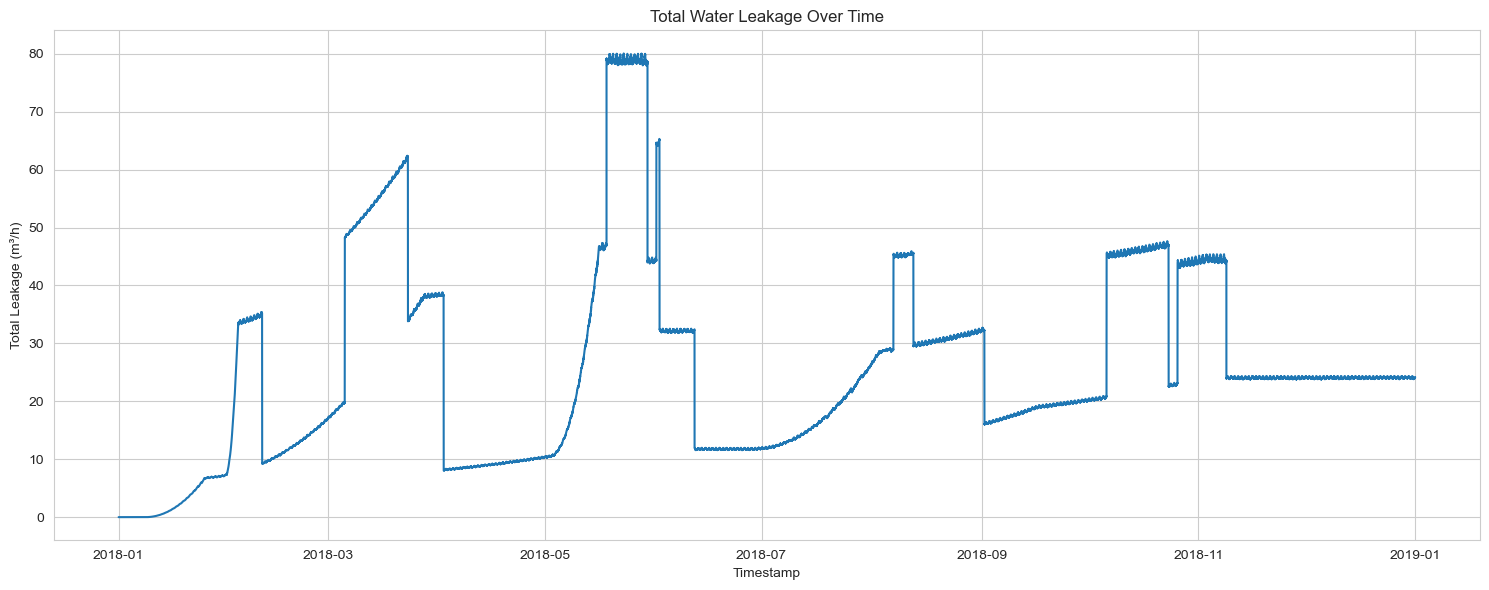

In [14]:
# Total leakage at each timestamp (kept as a separate Series; the leakage table is not modified)
total_leakage = leakage_data.sum(axis=1)

plt.figure(figsize=(15, 6))
plt.plot(leakages["Timestamp"], total_leakage)

plt.title("Total Water Leakage Over Time")
plt.xlabel("Timestamp")
plt.ylabel("Total Leakage (m³/h)")
plt.grid(True)
plt.tight_layout()
plt.show()

### Key Observations

- Total leakage flow varies significantly throughout 2018.
- Several sudden increases and decreases can be observed.
- The highest total leakage level occurs around May 2018.
- Leakage behavior is dynamic rather than constant over time.
- These variations highlight the importance of analyzing temporal patterns in water leakage data.

##  Leakage Distribution by Pipe

This section compares the distribution of leakage measurements across different network links using boxplots to identify variations in leakage behavior.

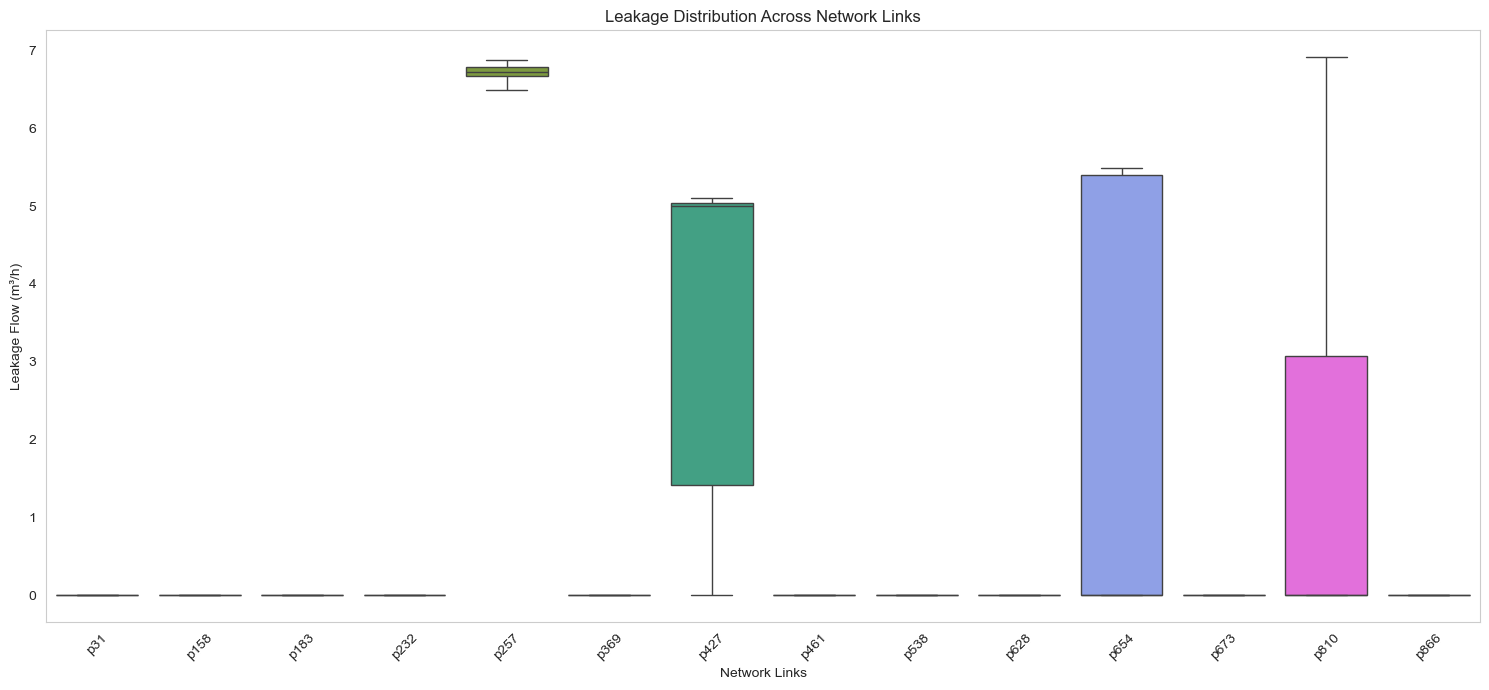

In [15]:
# Boxplot of all leakage measurements per link
plt.figure(figsize=(15, 7))

sns.boxplot(data=leakage_data, showfliers=False)

plt.title("Leakage Distribution Across Network Links")
plt.xlabel("Network Links")
plt.ylabel("Leakage Flow (m³/h)")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.tight_layout()
plt.show()

### Key Observations

- Leakage behavior varies significantly across network links.
- Link p257 shows a relatively concentrated distribution of leakage measurements.
- Links p427, p654, and p810 exhibit wider variations in their leakage distributions.
- Several links contain a high proportion of zero measurements.
- Including zero measurements affects the overall distribution and should be considered during further analysis.

## Non-Zero Leakage Distribution by Pipe

This section compares positive leakage measurements across network links, excluding zero values from the visualization to better understand leakage intensity during active measurements.

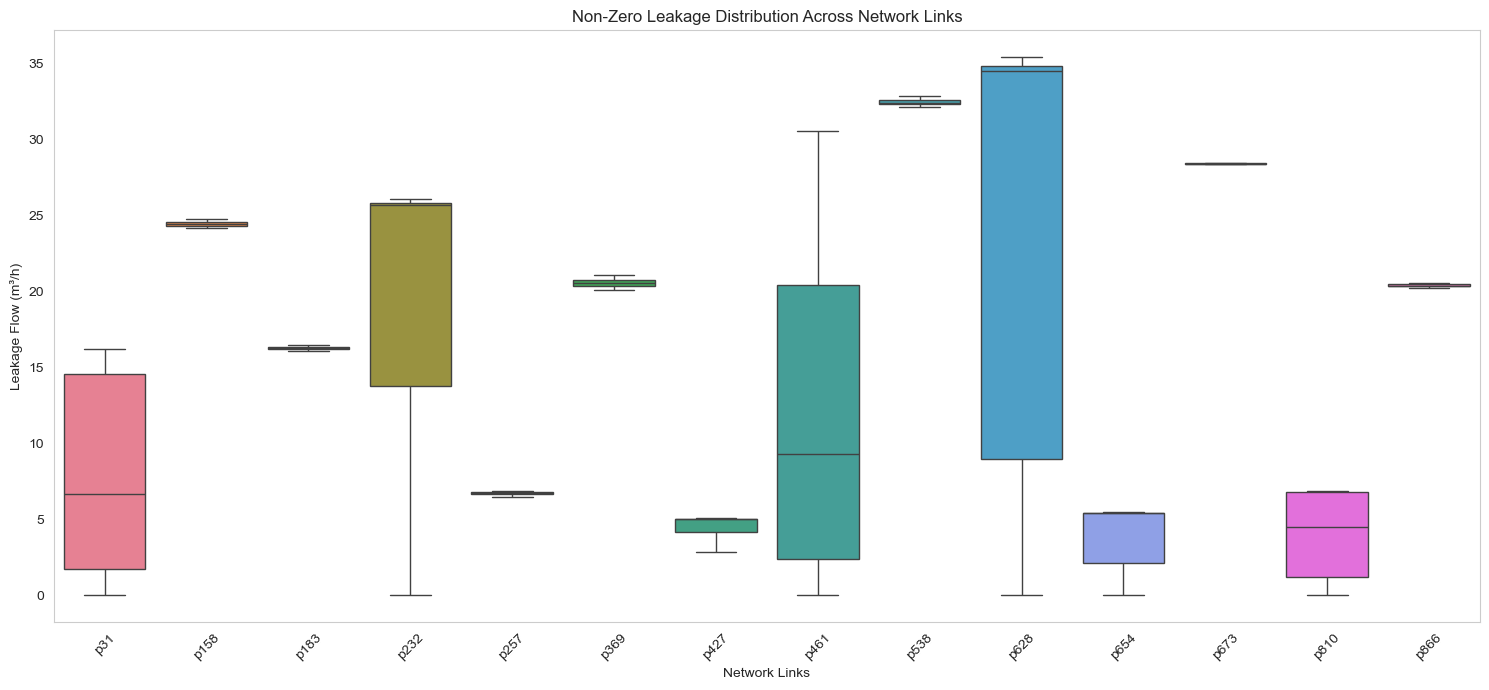

In [16]:
# Exclude Zero Leakage Measurements for Visualization

positive_leakage = leakage_data.where(leakage_data > 0)

# Plot Positive Leakage Distribution

plt.figure(figsize=(15, 7))

sns.boxplot(data=positive_leakage, showfliers=False)

plt.title("Non-Zero Leakage Distribution Across Network Links")
plt.xlabel("Network Links")
plt.ylabel("Leakage Flow (m³/h)")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.tight_layout()
plt.show()

### Key Observations

- Positive leakage measurements show different intensity levels across network links.
- Links p628, p538, p673, and p158 exhibit relatively high leakage flow measurements.
- Links p31, p232, p461, and p628 show considerable variations in their leakage measurements.
- Link p257 has a relatively concentrated distribution.
- Leakage intensity and leakage duration are different characteristics and should be analyzed separately.

## Average Non-Zero Leakage per Pipe

This section calculates and compares the average positive leakage flow for each network link.

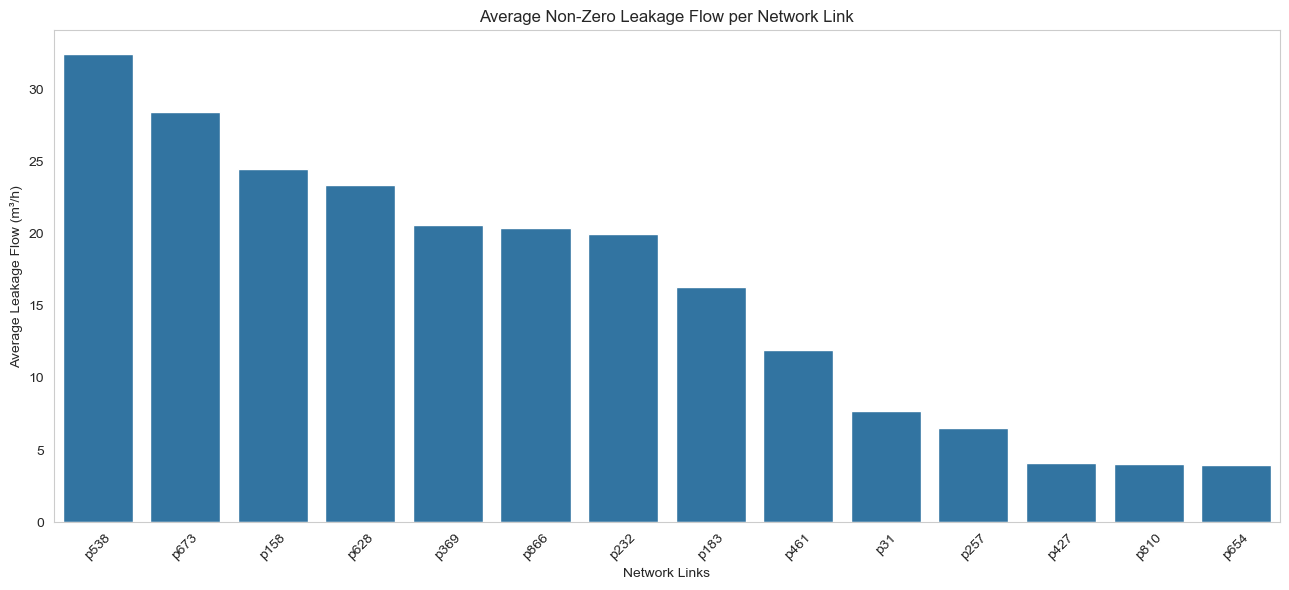

In [17]:
# Calculate Average Positive Leakage per Link

average_leakage = leakage_data.where(
    leakage_data > 0
).mean().sort_values(ascending=False)

# Plot Average Leakage

plt.figure(figsize=(13, 6))

sns.barplot(
    x=average_leakage.index,
    y=average_leakage.values
)

plt.title("Average Non-Zero Leakage Flow per Network Link")
plt.xlabel("Network Links")
plt.ylabel("Average Leakage Flow (m³/h)")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.tight_layout()
plt.show()

### Key Observations

- Link p538 has the highest average positive leakage flow.
- Links p673 and p158 also exhibit relatively high average leakage rates.
- Links p427, p810, and p654 have the lowest average positive leakage rates.
- Significant differences exist in leakage intensity across network links.
- Average leakage intensity does not necessarily represent total leakage volume or leakage duration.

##  Leakage Frequency per Pipe

This section compares the number of positive leakage measurements across network links to identify how frequently leakage activity was recorded.

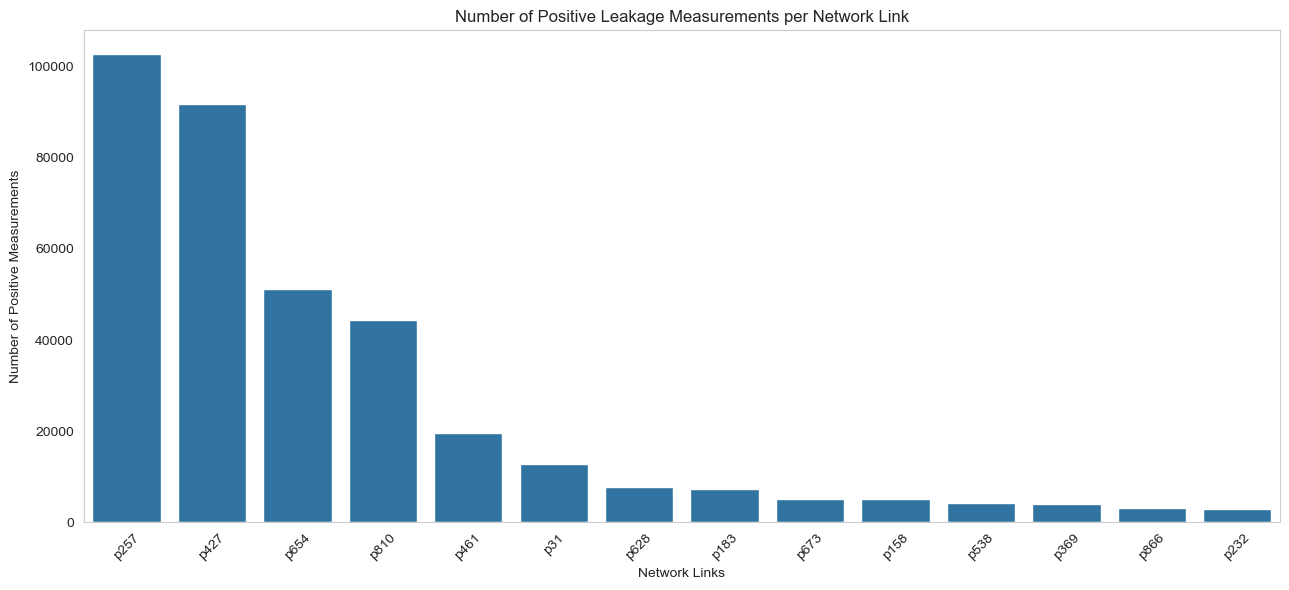

In [18]:
# Count Positive Leakage Measurements per Link

leakage_frequency = (
    (leakage_data > 0).sum()
    .sort_values(ascending=False)
)

# Plot Leakage Frequency

plt.figure(figsize=(13, 6))

sns.barplot(
    x=leakage_frequency.index,
    y=leakage_frequency.values
)

plt.title("Number of Positive Leakage Measurements per Network Link")
plt.xlabel("Network Links")
plt.ylabel("Number of Positive Measurements")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.tight_layout()
plt.show()

### Key Observations

- Link p257 has the highest number of positive leakage measurements.
- Link p427 has the second-highest number of positive measurements.
- Links p654 and p810 also show relatively frequent leakage activity.
- Links p232, p866, and p369 have the lowest numbers of positive measurements.
- The number of positive measurements provides an indication of leakage activity duration, rather than the number of separate leakage events.

##  Leakage Timeline Analysis

This section investigates leakage measurements over time for individual network links and compares the observed measurements with the documented leakage periods.

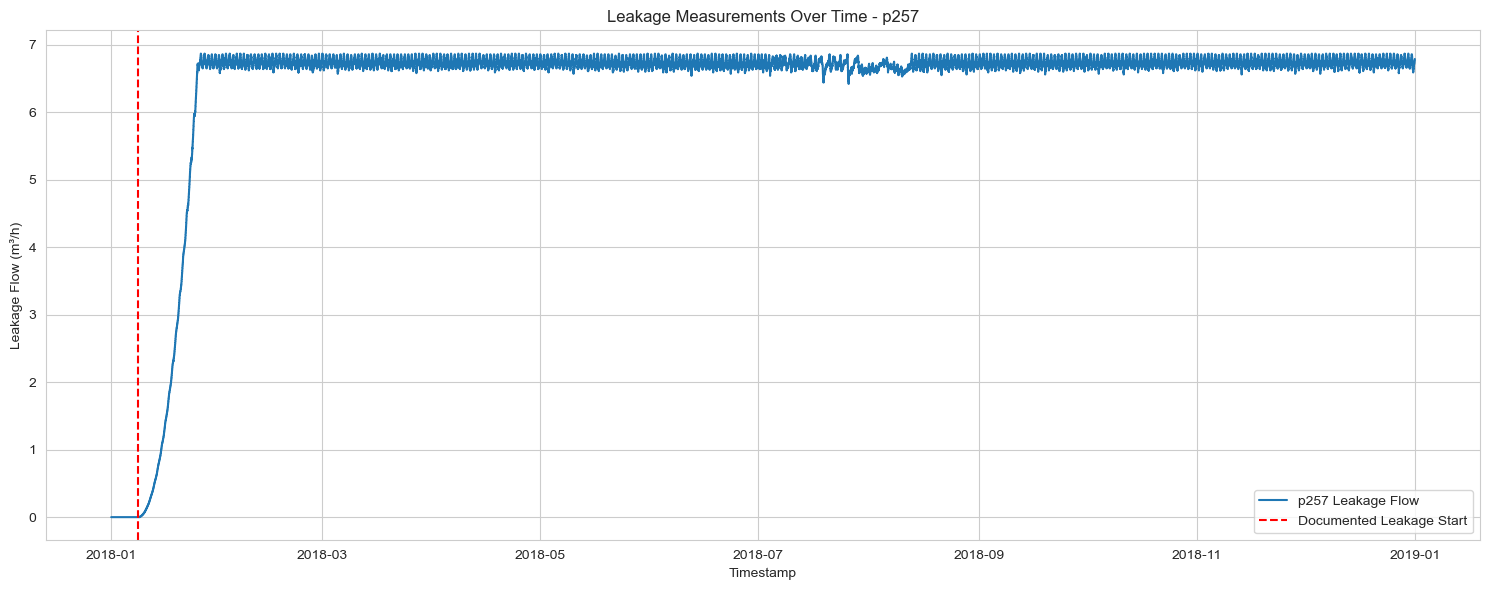

In [19]:
# Select a Network Link
link = "p257"

# Define Documented Leakage Start Time
leak_start = pd.Timestamp("2018-01-08 13:30")

# Plot Leakage Measurements Over Time
plt.figure(figsize=(15, 6))

plt.plot(
    leakages["Timestamp"],
    leakages[link],
    label=f"{link} Leakage Flow"
)

plt.axvline(
    leak_start,
    color="red",
    linestyle="--",
    label="Documented Leakage Start"
)

plt.title(f"Leakage Measurements Over Time - {link}")
plt.xlabel("Timestamp")
plt.ylabel("Leakage Flow (m³/h)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Key Observations

- Link p257 shows a gradual increase in leakage flow after the documented start time.
- The leakage flow gradually reaches a relatively stable level.
- The observed behavior is consistent with the documented incipient leakage type.
- The leakage measurements remain relatively stable throughout most of the observed period.
- This example demonstrates how leakage patterns can vary over time.
- The leakage flow remains at approximately 6.7 m³/h until the end of 2018, with no documented end time.

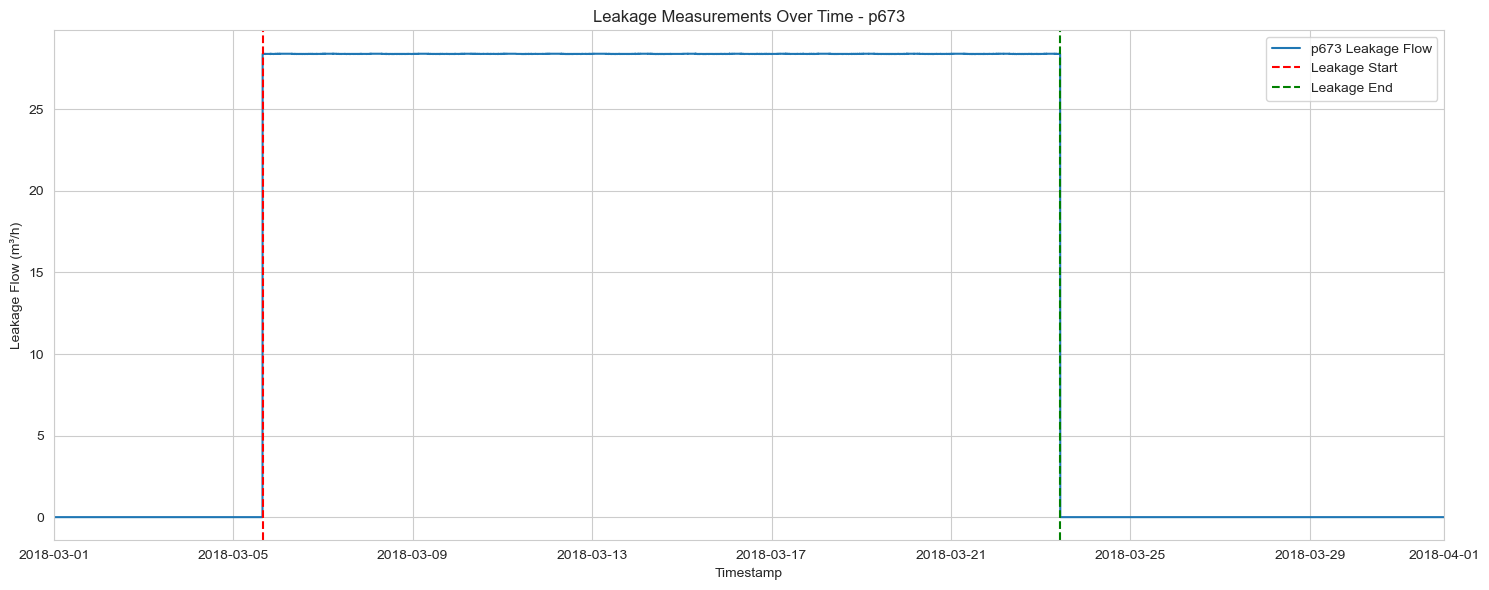

In [20]:
# Select Network Link
link = "p673"

# Define Documented Leakage Period
leak_start = pd.Timestamp("2018-03-05 15:45")
leak_end = pd.Timestamp("2018-03-23 10:25")

# Plot Leakage Measurements
plt.figure(figsize=(15, 6))

plt.plot(
    leakages["Timestamp"],
    leakages[link],
    label=f"{link} Leakage Flow"
)

plt.axvline(
    leak_start,
    color="red",
    linestyle="--",
    label="Leakage Start"
)

plt.axvline(
    leak_end,
    color="green",
    linestyle="--",
    label="Leakage End"
)

plt.xlim(
    pd.Timestamp("2018-03-01"),
    pd.Timestamp("2018-04-01")
)

plt.title(f"Leakage Measurements Over Time - {link}")
plt.xlabel("Timestamp")
plt.ylabel("Leakage Flow (m³/h)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Key Observations

- Link p673 shows an abrupt increase in leakage flow immediately after the documented start time.
- The leakage flow jumps directly to a constant level of approximately 28.4 m³/h, with no gradual ramp-up.
- The observed behavior is consistent with the documented abrupt leakage type.
- The leakage measurements remain essentially constant throughout the entire leakage period (about 18 days, from roughly March 5 to March 23, 2018).
- The leakage flow drops back to zero immediately after the documented end time, indicating that the network returns to normal conditions.
- This example demonstrates how an abrupt leakage produces a clear step-shaped pattern, in contrast to the gradual behavior seen in incipient leaks.

## Leakage Timeline for All Links

In this section, we plot the leakage flow of each network link over the full simulation period. The x-axis represents time steps, where each step corresponds to a 5-minute interval (105,120 time steps in total).

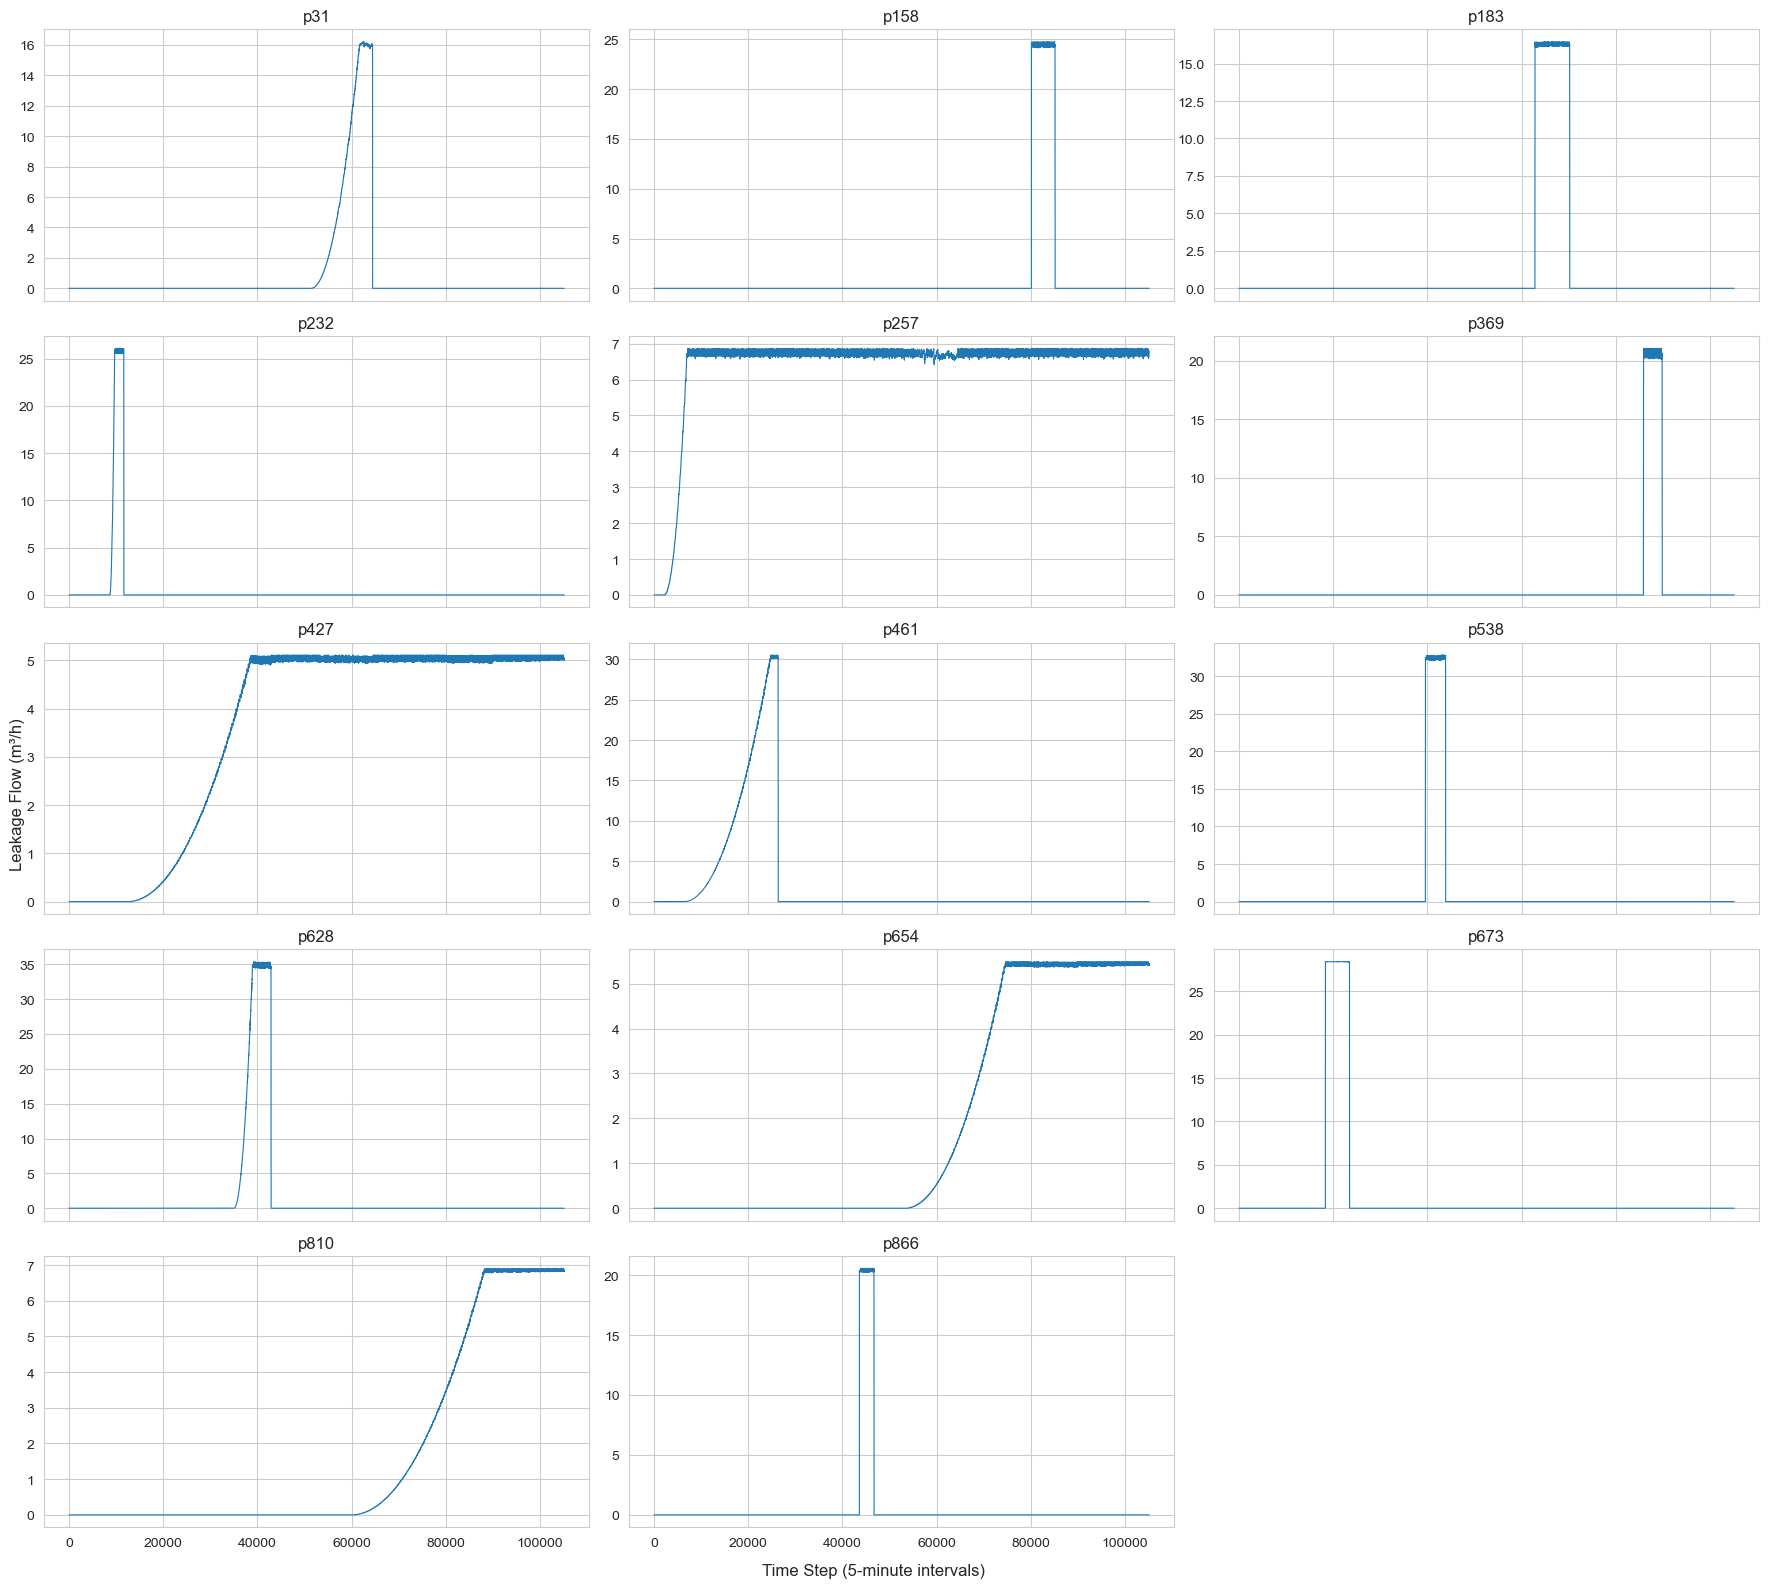

In [21]:
links = leakage_data.columns.tolist()
n_cols = 3
n_rows = int(np.ceil(len(links) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 3.2 * n_rows), sharex=True)
axes = axes.flatten()

for ax, link in zip(axes, links):
    ax.plot(leakage_data.index, leakage_data[link], linewidth=0.8)
    ax.set_title(link)
    ax.grid(True)

for ax in axes[len(links):]:
    ax.axis("off")

fig.supxlabel("Time Step (5-minute intervals)")
fig.supylabel("Leakage Flow (m³/h)")
plt.tight_layout()
plt.show()

## Leakage Timeline Observations

### p31
- Link p31 shows a single leakage event within a long simulation timeline of about 105,000 time steps.
- The leakage flow is zero from the beginning of the simulation until approximately time step 51,500.
- After the start time, the leakage flow increases gradually (with a smooth, curved ramp-up) rather than jumping suddenly.
- The leakage flow reaches a relatively stable level of approximately 16 m³/h around time step 62,000, with small fluctuations around the plateau.
- The leakage flow stays near this level until approximately time step 64,500, after which it drops abruptly to zero and stays at zero for the rest of the simulation.
- The observed behavior is consistent with the documented incipient leakage type.
- This example shows that the leakage event covers only a small fraction of the full timeline (around 12% of the data), which highlights the class imbalance between normal and leakage samples.

### p158
- Link p158 shows a single leakage event within a long simulation timeline of about 105,000 time steps.
- The leakage flow is zero from the beginning of the simulation until approximately time step 80,000.
- The leakage then rises abruptly to a level of approximately 24.5 m³/h, with no gradual ramp-up.
- The leakage flow stays at this level for about 5,000 time steps, until approximately time step 85,000, with small fluctuations around the plateau.
- The leakage flow drops back to zero immediately after the leakage ends and stays at zero for the rest of the simulation.
- The observed behavior is consistent with the documented abrupt leakage type.
- The leakage event covers only a small fraction of the full timeline (around 5% of the data).

### p183
- Link p183 shows a single leakage event within a long simulation timeline of about 105,000 time steps.
- The leakage flow is zero from the beginning of the simulation until approximately time step 63,000.
- The leakage then rises abruptly to a level of approximately 16.3 m³/h, with no gradual ramp-up.
- The leakage flow stays at this level for about 7,000 time steps, until approximately time step 70,000, with small fluctuations around the plateau.
- The leakage flow drops back to zero immediately after the leakage ends and stays at zero for the rest of the simulation.
- The observed behavior is consistent with the documented abrupt leakage type.
- The leakage event covers only a small fraction of the full timeline (around 7% of the data).

### p232
- Link p232 shows a single leakage event within a long simulation timeline of about 105,000 time steps.
- The leakage flow is zero from the beginning of the simulation until approximately time step 8,500.
- After the start time, the leakage flow increases rapidly but not instantaneously, following a short, steep ramp-up.
- The leakage flow reaches a plateau of approximately 26 m³/h around time step 10,000, with small fluctuations around this level.
- The leakage flow stays near this level until approximately time step 11,500, after which it drops abruptly to zero and stays at zero for the rest of the simulation.
- The observed behavior is consistent with the documented incipient leakage type, although the ramp-up is much shorter than in p31.
- The leakage event covers only a small fraction of the full timeline (around 3% of the data).

### p257
- The leakage starts at zero and begins growing gradually around time step 2,500.
- It reaches a stable level of about 6.7 m³/h at around time step 7,000.
- After reaching its peak, the leakage stays almost constant until the end of the timeline, so the leak is never repaired.
- A small temporary disturbance appears between time steps 57,000 and 65,000, after which the leakage returns to its previous level.
- This is a long-lasting, low-intensity leak, which explains the concentrated distribution seen in the boxplot.

### p369
- The leakage remains at zero for most of the timeline.
- It jumps abruptly to about 20 m³/h at around time step 85,700, with no gradual growth phase.
- The leak lasts for roughly 4,000 time steps, then drops suddenly back to zero at around time step 89,800.
- The flow stays stable around 20–21 m³/h during the event, with small fluctuations.
- This behavior suggests a sudden, short-lived leakage event that occurs late in the year.

### p427
- The leakage is zero until around time step 13,000.
- It then grows slowly and smoothly over a long period (about 25,000 time steps), reaching about 5 m³/h at around time step 38,500.
- After that, the leakage stays almost constant at about 5 m³/h until the end of the timeline.
- The slow growth indicates an incipient leak that gets worse gradually rather than a sudden burst.
- The leak is never repaired, which explains the wide spread of this link in the overall distribution.

### p461
- The leakage starts at about time step 6,500 and grows steadily in a curved pattern.
- It reaches a peak of about 30 m³/h at around time step 25,000, which makes it one of the most intense leaks in the dataset.
- The peak is held only briefly before the leakage drops abruptly to zero at around time step 26,300.
- The sudden drop suggests that the leak was detected and repaired.
- The leak is active only in the first quarter of the year, which matches the large variation seen for this link in the boxplot.

### p538
- The leakage is zero until around time step 39,500.
- It increases suddenly to about 32.5 m³/h, with no gradual growth phase.
- The leak stays stable for approximately 4,300 time steps, then drops abruptly to zero at around time step 43,800.
- Despite its short duration, it has a very high flow rate, which explains why p538 appears among the high-intensity links in the non-zero boxplot.
- This behavior is typical of a sudden burst that is repaired relatively quickly.

### p628
- The leakage begins at around time step 35,200 and rises rapidly to about 35 m³/h within roughly 4,000 time steps.
- This is the highest leakage level among all the plotted links.
- The leakage stays at its peak until around time step 43,000, then drops abruptly to zero.
- The growth phase is much steeper than in the incipient leaks (p257, p427, p654, p810), so this leak develops quickly.
- Its active period overlaps with p538, which explains the peak in total leakage observed around May 2018.

### p654
- The leakage stays at zero for more than half of the timeline, until around time step 54,000.
- It then grows slowly and smoothly, reaching about 5.4 m³/h at around time step 74,500.
- After reaching the peak, it stays stable until the end of the timeline, so the leak is never repaired.
- This is a late-starting, low-intensity leak with a long gradual growth phase.
- The high proportion of zero measurements for this link explains the wide variation seen in the boxplot that includes zeros.

### p673
- Link p673 shows a sudden increase in leakage flow from zero at approximately time step 18,000.
- The leakage flow jumps to a constant level of approximately 28.4 m³/h.
- The leakage measurements remain essentially constant throughout the leakage period.
- A sharp drop in leakage flow occurs at approximately time step 23,500, after which the flow returns to zero.
- This example demonstrates an abrupt leakage pattern, with the event covering only a small fraction of the full timeline.

### p810
- The leakage stays at zero until around time step 60,000.
- It then grows gradually and smoothly, reaching about 6.8 m³/h at around time step 88,000.
- The leakage remains stable at this level until the end of the timeline.
- Its growth pattern is similar to p427 and p654, which indicates an incipient leak that is never repaired.
- Because it starts late in the year, it contributes to total leakage only during the final part of the timeline.

### p866
- Link p866 shows a single leakage event within a long simulation timeline of about 105,000 time steps.
- The leakage flow is zero from the beginning of the simulation until approximately time step 43,500.
- The leakage then rises abruptly to a level of approximately 20.4 m³/h, with no gradual ramp-up.
- The leakage flow stays at this level for about 3,000 time steps, until approximately time step 46,500, with only small fluctuations around the plateau.
- The leakage flow drops back to zero immediately after the leakage ends and stays at zero for the rest of the simulation.
- The observed behavior is consistent with the documented abrupt leakage type.
- The leakage event covers only a small fraction of the full timeline (around 3% of the data).

## Very Small Leakage Values

Some links contain values of exactly `0.01` (and other tiny values) at the very start or end of an event. These come from the ramp-up of incipient leaks and are practically indistinguishable from "no leak". The next cell counts them, which motivates using a small positive threshold (`LEAK_THRESHOLD`) instead of `> 0` when the labels are created in Part 2.

In [22]:
tiny_values = pd.DataFrame({
    "Count == 0.01": (leakage_data == 0.01).sum(),
    "Count in (0, 0.05]": ((leakage_data > 0) & (leakage_data <= 0.05)).sum(),
    "Count > 0": (leakage_data > 0).sum(),
})
display(tiny_values)

,Count == 0.01,"Count in (0, 0.05]",Count > 0
p31,134,421,12864
p158,0,0,5029
p183,0,0,7376
p232,10,33,2948
p257,95,305,102810
p369,0,0,3965
p427,598,1911,91821
p461,172,544,19726
p538,0,0,4291
p628,34,108,7807


In [23]:
print("Data Types:")
print(leakage_data.dtypes)

print("\nMissing Values:")
print(leakage_data.isnull().sum())

print("\nNegative Values:")
print((leakage_data < 0).sum())

print("\nBasic Statistics:")
display(leakage_data.describe().T)

Data Types:
p31     float64
p158    float64
p183    float64
p232    float64
p257    float64
p369    float64
p427    float64
p461    float64
p538    float64
p628    float64
p654    float64
p673    float64
p810    float64
p866    float64
dtype: object

Missing Values:
p31     0
p158    0
p183    0
p232    0
p257    0
p369    0
p427    0
p461    0
p538    0
p628    0
p654    0
p673    0
p810    0
p866    0
dtype: int64

Negative Values:
p31     0
p158    0
p183    0
p232    0
p257    0
p369    0
p427    0
p461    0
p538    0
p628    0
p654    0
p673    0
p810    0
p866    0
dtype: int64

Basic Statistics:


,count,mean,std,min,25%,50%,75%,max
p31,105120.0,0.945125,3.299837,0.0,0.00,0.00,0.00,16.21
p158,105120.0,1.169352,5.216898,0.0,0.00,0.00,0.00,24.76
p183,105120.0,1.142639,4.159601,0.0,0.00,0.00,0.00,16.46
p232,105120.0,0.559364,3.640377,0.0,0.00,0.00,0.00,26.10
p257,105120.0,6.387721,1.390702,0.0,6.67,6.72,6.79,6.87
p369,105120.0,0.776125,3.920435,0.0,0.00,0.00,0.00,21.05
p427,105120.0,3.602963,2.075657,0.0,1.42,5.00,5.04,5.11
p461,105120.0,2.234977,6.427367,0.0,0.00,0.00,0.00,30.54
p538,105120.0,1.323949,6.417895,0.0,0.00,0.00,0.00,32.84
p628,105120.0,1.732674,7.159643,0.0,0.00,0.00,0.00,35.38


In [24]:
summary = pd.DataFrame(index=leakage_data.columns)

summary["Leakage_Count"] = (leakage_data > 0).sum()
summary["Zero_Count"] = (leakage_data == 0).sum()

summary["Leakage_Percentage"] = (
    summary["Leakage_Count"] / len(leakage_data) * 100
)

summary["Average_When_Leaking"] = leakage_data.where(
    leakage_data > 0
).mean()

summary["Maximum_Leakage"] = leakage_data.max()

summary = summary.round(2)

display(summary.sort_values(
    by="Leakage_Percentage",
    ascending=False
))

,Leakage_Count,Zero_Count,Leakage_Percentage,Average_When_Leaking,Maximum_Leakage
p257,102810,2310,97.80,6.53,6.87
p427,91821,13299,87.35,4.12,5.11
p654,51154,53966,48.66,4.00,5.49
p810,44416,60704,42.25,4.07,6.91
p461,19726,85394,18.77,11.91,30.54
p31,12864,92256,12.24,7.72,16.21
p628,7807,97313,7.43,23.33,35.38
p183,7376,97744,7.02,16.28,16.46
p673,5121,99999,4.87,28.40,28.42
p158,5029,100091,4.78,24.44,24.76


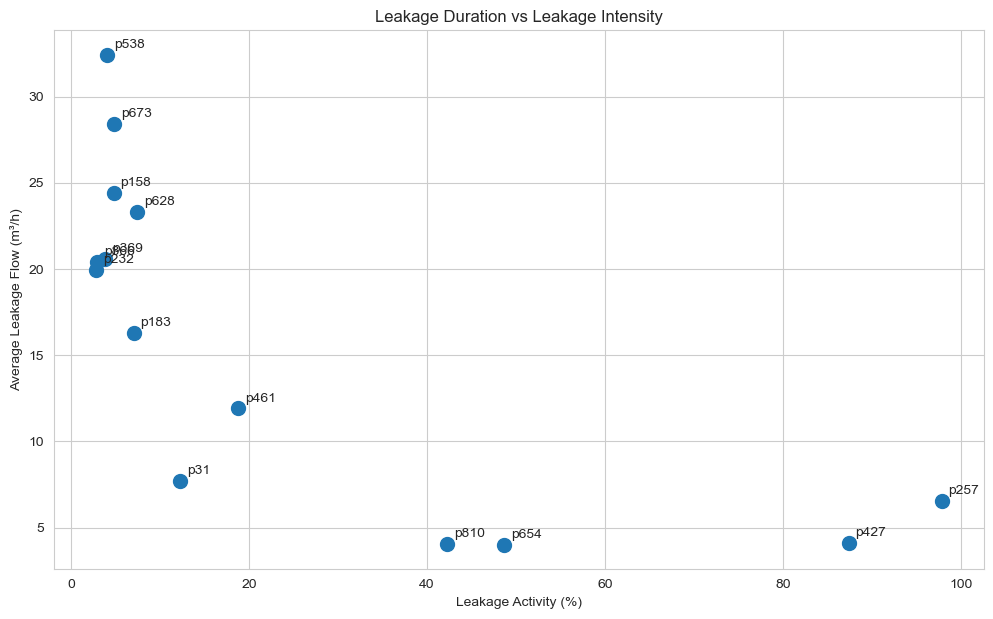

In [25]:
plt.figure(figsize=(12, 7))

plt.scatter(
    summary["Leakage_Percentage"],
    summary["Average_When_Leaking"],
    s=100
)

for link in summary.index:
    plt.annotate(
        link,
        (
            summary.loc[link, "Leakage_Percentage"],
            summary.loc[link, "Average_When_Leaking"]
        ),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Leakage Activity (%)")
plt.ylabel("Average Leakage Flow (m³/h)")
plt.title("Leakage Duration vs Leakage Intensity")
plt.grid(True)
plt.show()

In [26]:
# Each measurement represents 5 minutes
interval_hours = 5 / 60

# Calculate total leaked water for each link
total_water_loss = leakage_data.sum() * interval_hours

# Create summary table
water_loss_summary = pd.DataFrame({
    "Total_Water_Loss_m3": total_water_loss
})

water_loss_summary = water_loss_summary.sort_values(
    by="Total_Water_Loss_m3",
    ascending=False
)

display(water_loss_summary.round(2))

,Total_Water_Loss_m3
p257,55956.44
p427,31561.95
p461,19578.40
p654,17041.98
p628,15178.22
p810,15064.08
p673,12120.54
p538,11597.80
p158,10243.52
p183,10009.51


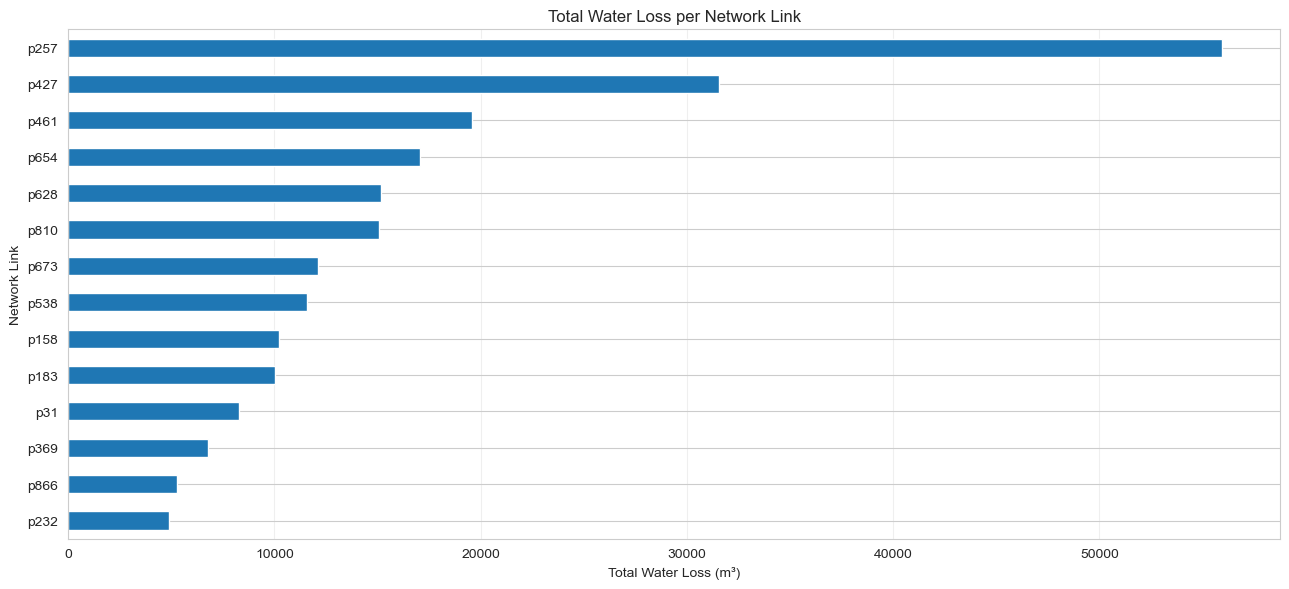

In [27]:
plt.figure(figsize=(13, 6))

water_loss_summary.sort_values(
    "Total_Water_Loss_m3",
    ascending=True
)["Total_Water_Loss_m3"].plot(
    kind="barh"
)

plt.title("Total Water Loss per Network Link")
plt.xlabel("Total Water Loss (m³)")
plt.ylabel("Network Link")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## Pressure and Flow Data Quality Check

Quick checks of the SCADA sensor files before they are merged in Part 2.

In [28]:
print("PRESSURES DATA")
print("Shape:", pressures.shape)
print("Columns:", pressures.columns.tolist())
display(pressures.head())

print("\nFLOWS DATA")
print("Shape:", flows.shape)
print("Columns:", flows.columns.tolist())
display(flows.head())

PRESSURES DATA
Shape: (105120, 34)
Columns: ['Timestamp', 'n1', 'n4', 'n31', 'n54', 'n105', 'n114', 'n163', 'n188', 'n215', 'n229', 'n288', 'n296', 'n332', 'n342', 'n410', 'n415', 'n429', 'n458', 'n469', 'n495', 'n506', 'n516', 'n519', 'n549', 'n613', 'n636', 'n644', 'n679', 'n722', 'n726', 'n740', 'n752', 'n769']


,Timestamp,n1,n4,n31,n54,n105,n114,n163,n188,n215,...,n549,n613,n636,n644,n679,n722,n726,n740,n752,n769
0,2018-01-01 00:00:00,28.92,33.87,37.13,37.13,50.52,53.99,52.56,55.32,39.09,...,54.80,56.16,45.53,47.62,47.33,46.14,47.12,43.81,49.17,48.50
1,2018-01-01 00:05:00,28.94,33.89,37.16,37.23,50.60,54.09,52.67,55.42,39.10,...,54.90,56.26,45.61,47.71,47.39,46.19,47.17,43.83,49.22,48.54
2,2018-01-01 00:10:00,28.96,33.91,37.18,37.21,50.57,54.05,52.64,55.39,39.09,...,54.87,56.24,45.61,47.71,47.41,46.20,47.19,43.84,49.24,48.56
3,2018-01-01 00:15:00,28.98,33.93,37.19,37.27,50.60,54.08,52.70,55.45,39.09,...,54.92,56.30,45.65,47.75,47.43,46.21,47.21,43.84,49.26,48.57
4,2018-01-01 00:20:00,28.98,33.93,37.19,37.14,50.53,54.00,52.57,55.32,39.09,...,54.80,56.17,45.54,47.64,47.34,46.15,47.13,43.81,49.17,48.50



FLOWS DATA
Shape: (105120, 4)
Columns: ['Timestamp', 'p227', 'p235', 'PUMP_1']


,Timestamp,p227,p235,PUMP_1
0,2018-01-01 00:00:00,77.77,83.93,44.04
1,2018-01-01 00:05:00,72.51,76.34,44.06
2,2018-01-01 00:10:00,71.54,78.68,44.06
3,2018-01-01 00:15:00,69.85,75.50,44.07
4,2018-01-01 00:20:00,77.12,82.99,44.03


In [29]:
# 1. Check missing values
print("Missing Values")
print("Pressure:", pressures.isnull().sum().sum())
print("Flow:", flows.isnull().sum().sum())

# 2. Check data types
print("\nPressure Data Types:")
print(pressures.dtypes.value_counts())

print("\nFlow Data Types:")
print(flows.dtypes.value_counts())

# 3. Check timestamps
print("\nTimestamp Information")

print("Pressure Timestamp Type:",
      pressures["Timestamp"].dtype)

print("Flow Timestamp Type:",
      flows["Timestamp"].dtype)

print("Pressure Duplicate Timestamps:",
      pressures["Timestamp"].duplicated().sum())

print("Flow Duplicate Timestamps:",
      flows["Timestamp"].duplicated().sum())

# 4. Compare timestamps
print("\nAre timestamps identical?",
      pressures["Timestamp"].equals(flows["Timestamp"]))

# 5. Display time range
print("\nPressure Time Range:")
print(pressures["Timestamp"].min(),
      "to",
      pressures["Timestamp"].max())

print("\nFlow Time Range:")
print(flows["Timestamp"].min(),
      "to",
      flows["Timestamp"].max())

Missing Values
Pressure: 0
Flow: 0

Pressure Data Types:
float64           33
datetime64[ns]     1
Name: count, dtype: int64

Flow Data Types:
float64           3
datetime64[ns]    1
Name: count, dtype: int64

Timestamp Information
Pressure Timestamp Type: datetime64[ns]
Flow Timestamp Type: datetime64[ns]
Pressure Duplicate Timestamps: 0
Flow Duplicate Timestamps: 0

Are timestamps identical? True

Pressure Time Range:
2018-01-01 00:00:00 to 2018-12-31 23:55:00

Flow Time Range:
2018-01-01 00:00:00 to 2018-12-31 23:55:00


## Summary and Next Step

- All three files share identical 5-minute timestamps (105,120 rows for 2018) with no missing values or duplicates.
- The leakage file uses decimal commas and is now read correctly with `decimal=","`.
- Leakage behaviour differs strongly between links (duration, intensity, abrupt vs. incipient). Several links leak for the whole year while others have one short event.
- Very small values (≈0.01) exist and need a threshold when defining labels.

Part 2 builds the targets, engineered features and a time-aware train/validation/test split.

# Part 2: Preprocessing and Feature Engineering
### Where Is The Leak? - Water Leakage Detection & Localization

This notebook prepares everything the models need:

1. Configuration of the key design choices.
2. Merging the sensor files and the leakage labels.
3. Target definition (detection and localization).
4. Causal feature engineering.
5. A **blocked, time-aware** train / validation / test split.
6. Feature selection (training data only).
7. Saving the prepared data for Part 3.

## Part 2 - Step 1: Imports and Configuration

In [30]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import joblib
from sklearn.feature_selection import mutual_info_classif

warnings.filterwarnings("ignore")

# ------------------------------------------------------------------
# Key design choices (change them here, everything below follows)
# ------------------------------------------------------------------
SEED = 42

# A link counts as "leaking" when its leakage flow is above this value (m3/h).
# 0.01-0.05 values are ramp-up/ramp-down noise of incipient leaks (see Part 1).
LEAK_THRESHOLD = 0.05

# Links ignored when defining the NETWORK-LEVEL detection target.
# p257 leaks from 2018-01-08 until the end of the year, so "any leak" is identical to p257
# and detection would become trivial. Set to [] to use the plain "any leak" target.
DETECTION_EXCLUDE_LINKS = ["p257"]

# Rolling windows in 5-minute steps: 15 min, 1 h, 6 h; and a 12 h baseline window
ROLL_WINDOWS = [3, 12, 72]
BASELINE_WINDOW = 144

# Blocked split: the year is cut into blocks of 5 days; whole blocks go to train/val/test.
BLOCK_SIZE = 1440
GAP = 144            # 12 h of rows removed on both sides of a block boundary between different splits
TRAIN_FRAC, VAL_FRAC = 0.70, 0.15

N_DET_FEATURES = 20
N_LOC_FEATURES_PER_LINK = 10
MI_SAMPLE_SIZE = 10000

PROJECT_DIR = Path.cwd().parent
DATA_DIR = next(
    (p for p in [Path.cwd() / "Dataset", PROJECT_DIR / "Dataset"] if p.exists()), None
)
if DATA_DIR is None:
    raise FileNotFoundError("Dataset folder not found next to the notebook or in its parent folder.")

ARTIFACT_DIR = PROJECT_DIR / "artifacts"
ARTIFACT_DIR.mkdir(exist_ok=True)
print("Data folder:", DATA_DIR)
print("Artifacts folder:", ARTIFACT_DIR)

Data folder: c:\Users\dell\Desktop\Next Gen\Dataset
Artifacts folder: c:\Users\dell\Desktop\Next Gen\artifacts


## Part 2 - Step 2: Loading and Merging the Data

The three files are read with `decimal=","` and their timestamps are verified to be identical and regular (5 minutes) before they are combined. The leakage values are **not** merged into the feature table, so no label information can leak into the inputs.

In [31]:
READ_KW = dict(sep=";", decimal=",", parse_dates=["Timestamp"])

leakages = pd.read_csv(DATA_DIR / "2018_Leakages.csv", **READ_KW)
flows = pd.read_csv(DATA_DIR / "2018_SCADA_Flows.csv", **READ_KW)
pressures = pd.read_csv(DATA_DIR / "2018_SCADA_Pressures.csv", **READ_KW)

# Timestamps must match exactly and be regularly spaced
assert leakages["Timestamp"].equals(flows["Timestamp"]), "Leakage/Flow timestamps differ"
assert leakages["Timestamp"].equals(pressures["Timestamp"]), "Leakage/Pressure timestamps differ"
assert (leakages["Timestamp"].diff().dropna() == pd.Timedelta(minutes=5)).all(), "Timestamps are not 5-minute regular"

sensor_data = pd.merge(pressures, flows, on="Timestamp", how="inner", validate="one_to_one")
sensor_cols = [col for col in sensor_data.columns if col != "Timestamp"]
leakage_cols = [col for col in leakages.columns if col != "Timestamp"]

leak_values = leakages[leakage_cols].reset_index(drop=True)

print("Sensor data:", sensor_data.shape, "| Missing values:", int(sensor_data.isnull().sum().sum()))
print("Sensors:", len(sensor_cols), "| Leakage links:", len(leakage_cols))

Sensor data: (105120, 37) | Missing values: 0
Sensors: 36 | Leakage links: 14


## Part 2 - Step 3: Target Definition

Two targets are built from the leakage table:

- **Localization (multi-label):** one binary column per link, `1` when its leakage flow is above `LEAK_THRESHOLD`.
- **Detection (binary):** `1` when at least one link (excluding `DETECTION_EXCLUDE_LINKS`) is leaking, otherwise `0` (normal).

**Why p257 is excluded from the detection target.** In this dataset p257 is active in every observation in which any link leaks, so the plain "any leak" target is exactly the p257 label (97.8 % positives and only the first 8 days as "normal"). That target is almost trivial and rewards a model that only recognises the start of the year. Detection is therefore defined as "a leak other than the long-lasting p257 leak is active". The localization task still includes p257.

In [32]:
y_loc = (leak_values > LEAK_THRESHOLD).astype(int)

det_links = [col for col in leakage_cols if col not in DETECTION_EXCLUDE_LINKS]
y_det = y_loc[det_links].any(axis=1).astype(int)
y_any = y_loc.any(axis=1).astype(int)

print("Plain 'any leak' target is identical to p257:",
      bool((y_any == y_loc["p257"]).all()) if "p257" in y_loc else "p257 not present")

print("\nDetection target (1 = leak, 0 = normal):")
print(y_det.value_counts().sort_index())
print((y_det.value_counts(normalize=True).sort_index() * 100).round(2).astype(str) + " %")

first_leak = y_det.idxmax()
print(f"\nFirst leak step: {first_leak} ({sensor_data['Timestamp'].iloc[first_leak]})")
print("Is 'normal' one single contiguous period at the start?",
      bool((y_det.iloc[:first_leak] == 0).all() and (y_det.iloc[first_leak:] == 1).all()))

print("\nLocalization positives per link:")
print(y_loc.sum().sort_values(ascending=False))

print("\nNumber of simultaneously leaking links:")
print(y_loc.sum(axis=1).value_counts().sort_index())

Plain 'any leak' target is identical to p257: True

Detection target (1 = leak, 0 = normal):
0     7167
1    97953
Name: count, dtype: int64
0     6.82 %
1    93.18 %
Name: proportion, dtype: object

First leak step: 7167 (2018-01-25 21:15:00)
Is 'normal' one single contiguous period at the start? True

Localization positives per link:
p257    102505
p427     89910
p654     49659
p810     42652
p461     19182
p31      12443
p628      7699
p183      7376
p673      5121
p158      5029
p538      4291
p369      3965
p866      3096
p232      2915
dtype: int64

Number of simultaneously leaking links:
0     2615
1     4552
2    19260
3    20338
4    41638
5    15097
6     1620
Name: count, dtype: int64


## Part 2 - Step 4: Feature Engineering

All features are **causal**: each value only uses the current and past observations, never future ones. For every sensor (33 pressures, 2 flows and the pump flow):

| Feature | Meaning |
|---|---|
| raw value | original measurement |
| `_diff` | change from the previous step |
| `_mean{w}` / `_std{w}` | rolling mean / standard deviation over 15 min, 1 h and 6 h |
| `_dev{w}` | deviation of the current value from the 12-hour rolling mean (removes slow demand patterns) |

Features are computed on the full continuous series (so windows are not cut at split boundaries); the split below removes the rows around block boundaries so that no window overlaps another split's data.

In [33]:
def build_features(df, cols, windows=ROLL_WINDOWS, baseline=BASELINE_WINDOW):
    """Causal features for 5-minute sensor data (rows must be in time order)."""
    base = df[cols].reset_index(drop=True).astype(float)
    parts = [base]

    parts.append(base.diff().fillna(0).add_suffix("_diff"))

    for w in windows:
        roll = base.rolling(window=w, min_periods=1)
        parts.append(roll.mean().add_suffix(f"_mean{w}"))
        parts.append(base.rolling(window=w, min_periods=2).std().fillna(0).add_suffix(f"_std{w}"))

    baseline_mean = base.rolling(window=baseline, min_periods=1).mean()
    parts.append((base - baseline_mean).add_suffix(f"_dev{baseline}"))

    return pd.concat(parts, axis=1)

X_all = build_features(sensor_data, sensor_cols)

print("Feature matrix:", X_all.shape)
print("Missing values:", int(X_all.isnull().sum().sum()))
print("Infinite values:", int(np.isinf(X_all.values).sum()))

Feature matrix: (105120, 324)
Missing values: 0
Infinite values: 0


## Part 2 - Step 5: Blocked Train / Validation / Test Split

**Why not a random split?** Neighbouring 5-minute rows are almost identical, and every leak is a single event in time. A random split puts near-copies of the same rows in train and test, so the scores mostly measure memorisation. A purely chronological split (first 70 % / next 15 % / last 15 %) fails too: all normal observations are at the start of the year, so validation and test would contain no normal data.

**Approach used here:**

1. The year is cut into blocks of 5 days.
2. Whole blocks are assigned to train (70 %), validation (15 %) and test (15 %). The assignment is searched over random seeds so that every split contains enough normal data and as many links as possible have enough leak examples in every split.
3. A 12-hour gap is removed on both sides of each boundary between blocks of different splits, and the first rows of the year (incomplete rolling windows) are dropped. No rolling window therefore reaches across splits.

In [34]:
n = len(sensor_data)
block_id = np.arange(n) // BLOCK_SIZE
n_blocks = int(block_id.max()) + 1
pos_in_block = np.arange(n) % BLOCK_SIZE

pos_by_block = y_loc.groupby(block_id).sum().values           # (blocks, links)
normal_by_block = (1 - y_det).groupby(block_id).sum().values   # (blocks,)

def assign_blocks(seed):
    rng = np.random.default_rng(seed)
    order = rng.permutation(n_blocks)
    n_train = int(round(TRAIN_FRAC * n_blocks))
    n_val = int(round(VAL_FRAC * n_blocks))
    split = np.empty(n_blocks, dtype=int)          # 0 = train, 1 = validation, 2 = test
    split[order[:n_train]] = 0
    split[order[n_train:n_train + n_val]] = 1
    split[order[n_train + n_val:]] = 2
    return split

def split_score(split):
    normals = np.array([normal_by_block[split == s].sum() for s in range(3)])
    if normals[0] < 1000 or normals[1] < 300 or normals[2] < 300:
        return -1                                   # every split needs normal data
    pos = np.stack([pos_by_block[split == s].sum(axis=0) for s in range(3)])
    covered = (pos[0] >= 200) & (pos[1] >= 20) & (pos[2] >= 20)
    return int(covered.sum())

best_seed, best_score = None, -1
for seed in range(2000):
    score = split_score(assign_blocks(seed))
    if score > best_score:
        best_seed, best_score = seed, score

if best_score < 0:
    raise RuntimeError("No block assignment gives every split enough normal data; reduce BLOCK_SIZE.")

block_split = assign_blocks(best_seed)
print(f"Selected block assignment seed: {best_seed} "
      f"({best_score} of {len(leakage_cols)} links have enough examples in train, validation and test)")

Selected block assignment seed: 243 (12 of 14 links have enough examples in train, validation and test)


In [35]:
row_split = block_split[block_id]
prev_split = np.where(block_id > 0, block_split[np.maximum(block_id - 1, 0)], row_split)
next_split = np.where(block_id < n_blocks - 1, block_split[np.minimum(block_id + 1, n_blocks - 1)], row_split)

drop = (
    ((pos_in_block < GAP) & (prev_split != row_split))
    | ((pos_in_block >= BLOCK_SIZE - GAP) & (next_split != row_split))
    | (np.arange(n) < BASELINE_WINDOW)          # incomplete rolling windows at the start of the year
)

idx_train = np.where((row_split == 0) & ~drop)[0]
idx_val = np.where((row_split == 1) & ~drop)[0]
idx_test = np.where((row_split == 2) & ~drop)[0]

print(f"Rows removed around boundaries/warm-up: {int(drop.sum())}")
print(f"Train: {len(idx_train)} | Validation: {len(idx_val)} | Test: {len(idx_test)}")

summary = pd.DataFrame({
    "Rows": [len(idx_train), len(idx_val), len(idx_test)],
    "Normal rows": [int((y_det.iloc[i] == 0).sum()) for i in (idx_train, idx_val, idx_test)],
    "Leak rows": [int((y_det.iloc[i] == 1).sum()) for i in (idx_train, idx_val, idx_test)],
}, index=["Train", "Validation", "Test"])
summary["Normal %"] = (summary["Normal rows"] / summary["Rows"] * 100).round(2)
display(summary)

per_link = pd.DataFrame({
    "Train": y_loc.iloc[idx_train].sum(),
    "Validation": y_loc.iloc[idx_val].sum(),
    "Test": y_loc.iloc[idx_test].sum(),
})
display(per_link)

weak = per_link[(per_link["Train"] < 200) | (per_link["Validation"] < 20) | (per_link["Test"] < 20)]
if len(weak):
    print("Links with few examples in at least one split (their scores are less reliable):",
          weak.index.tolist())

Rows removed around boundaries/warm-up: 10224
Train: 68976 | Validation: 12960 | Test: 12960


,Rows,Normal rows,Leak rows,Normal %
Train,68976,2304,66672,3.34
Validation,12960,2592,10368,20.00
Test,12960,1152,11808,8.89


,Train,Validation,Test
p31,8987,1152,1152
p158,2592,421,1152
p183,2304,1328,2592
p232,2658,0,0
p257,67824,12960,11929
p369,1830,407,1152
p427,60534,9216,11808
p461,13821,2304,1152
p538,1946,1152,617
p628,3091,2304,1152


Links with few examples in at least one split (their scores are less reliable): ['p232', 'p866']


## Part 2 - Step 6: Feature Selection (Training Data Only)

Mutual Information is computed on a random subsample of the **training** rows only, so validation and test data cannot influence the selection:

- **Detection:** the top features by Mutual Information with the detection target.
- **Localization:** the top features for each link; the union over all links is used.

Tree-based models are insensitive to feature scale, so no scaling step is applied.

In [36]:

import time

start_time = time.time()

# Prepare training data
X_train = X_all.iloc[idx_train]
y_det_train = y_det.iloc[idx_train]
y_loc_train = y_loc.iloc[idx_train]

rng = np.random.default_rng(SEED)
mi_rows = rng.choice(
    len(X_train),
    size=min(MI_SAMPLE_SIZE, len(X_train)),
    replace=False
)

X_mi = X_train.iloc[mi_rows]

# Detection Feature Selection
det_scores = pd.Series(
    mutual_info_classif(
        X_mi,
        y_det_train.iloc[mi_rows],
        random_state=SEED,
        n_jobs=-1
    ),
    index=X_train.columns
).sort_values(ascending=False)

selected_detection_features = det_scores.head(
    N_DET_FEATURES
).index.tolist()


# Localization Feature Selection
loc_scores = {}

for i, link in enumerate(y_loc_train.columns, 1):

    y_link = y_loc_train[link].iloc[mi_rows]

    if y_link.nunique() < 2:
        loc_scores[link] = pd.Series(
            0.0,
            index=X_train.columns
        )

    else:
        loc_scores[link] = pd.Series(
            mutual_info_classif(
                X_mi,
                y_link,
                random_state=SEED,
                n_jobs=-1
            ),
            index=X_train.columns
        )

    if i % 10 == 0:
        print(f"Processed {i}/{len(y_loc_train.columns)} links")


loc_scores = pd.DataFrame(loc_scores)

selected_localization_features = sorted({
    feat
    for link in loc_scores.columns
    for feat in loc_scores[link]
        .sort_values(ascending=False)
        .head(N_LOC_FEATURES_PER_LINK).index
})


# Results
print("\nTop detection features:")
display(det_scores.head(10).to_frame("Mutual Information"))

print("Detection features:", len(selected_detection_features))
print("Localization features:", len(selected_localization_features))

print(f"\nExecution time: {(time.time() - start_time)/60:.2f} minutes")


Processed 10/14 links

Top detection features:


,Mutual Information
n1_std3,0.058095
n31_std3,0.056394
n4_std3,0.051382
n215_std12,0.045530
n740_std3,0.044149
n215_std72,0.039950
n1_mean72,0.033684
n215_std3,0.031514
n722_mean72,0.029392
n54_mean12,0.029076


Detection features: 20
Localization features: 82

Execution time: 1.39 minutes


## Part 2 - Step 7: Saving the Prepared Data

In [37]:
all_selected = sorted(set(selected_detection_features) | set(selected_localization_features))

prepared = {
    "X_train": X_all.iloc[idx_train][all_selected].astype("float32"),
    "X_val": X_all.iloc[idx_val][all_selected].astype("float32"),
    "X_test": X_all.iloc[idx_test][all_selected].astype("float32"),
    "y_det_train": y_det.iloc[idx_train], "y_det_val": y_det.iloc[idx_val], "y_det_test": y_det.iloc[idx_test],
    "y_loc_train": y_loc.iloc[idx_train], "y_loc_val": y_loc.iloc[idx_val], "y_loc_test": y_loc.iloc[idx_test],
    "selected_detection_features": selected_detection_features,
    "selected_localization_features": selected_localization_features,
    "config": {
        "SEED": SEED, "LEAK_THRESHOLD": LEAK_THRESHOLD,
        "DETECTION_EXCLUDE_LINKS": DETECTION_EXCLUDE_LINKS,
        "ROLL_WINDOWS": ROLL_WINDOWS, "BASELINE_WINDOW": BASELINE_WINDOW,
        "BLOCK_SIZE": BLOCK_SIZE, "GAP": GAP, "block_split_seed": best_seed,
        "sensor_columns": sensor_cols,
    },
}

# Row positions (time order) are saved too; they are only used for a sanity check in Part 3
prepared["row_idx_train"], prepared["row_idx_val"], prepared["row_idx_test"] = idx_train, idx_val, idx_test

joblib.dump(prepared, ARTIFACT_DIR / "prepared_data.joblib")
print("Saved:", ARTIFACT_DIR / "prepared_data.joblib")
print("Train/Val/Test feature shapes:",
      prepared["X_train"].shape, prepared["X_val"].shape, prepared["X_test"].shape)

Saved: c:\Users\dell\Desktop\Next Gen\artifacts\prepared_data.joblib
Train/Val/Test feature shapes: (68976, 87) (12960, 87) (12960, 87)


### Notes and Limitations

- The "normal" class is one single period at the start of the year (before the first leak other than p257 starts, with the default configuration), so detection has limited variety in normal conditions.
- Each link has essentially one leak event, so the localization models are tested on *other times of the same events*, not on completely new events. The scores show how well the sensor patterns identify each known leak; they do not prove generalisation to leaks that were never seen.
- Links with few examples in a split are flagged above and should be interpreted with caution.

# Part 3: Modeling and Evaluation
### Where Is The Leak? - Water Leakage Detection & Localization

Two tasks are modelled with two tree-ensemble algorithms (Random Forest and Extra Trees):

- **Leak Detection:** binary, `1` = leak, `0` = normal.
- **Leak Localization:** multi-label, one output per network link.

**Evaluation protocol**

1. Both algorithms are trained on the training split.
2. They are compared **on the validation split only**, and one algorithm per task is selected.
3. The test split is used **once**, for the selected models.
4. Because "normal" is the rare and important class in detection, it is treated as the positive class for the main detection metrics (precision, recall, F1, PR-AUC), together with Balanced Accuracy and MCC. Plain accuracy is not used for model selection.

## Part 3 - Step 1: Imports and Loading the Prepared Data

In [38]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.multioutput import MultiOutputClassifier
from sklearn.metrics import (
    precision_score, recall_score, f1_score, balanced_accuracy_score,
    matthews_corrcoef, roc_auc_score, average_precision_score,
    confusion_matrix, precision_recall_fscore_support, hamming_loss,
    multilabel_confusion_matrix
)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

PROJECT_DIR = Path.cwd().parent
ARTIFACT_DIR = PROJECT_DIR / "artifacts"
data_file = ARTIFACT_DIR / "prepared_data.joblib"
if not data_file.exists():
    raise FileNotFoundError("Run Part 2 first: " + str(data_file))

d = joblib.load(data_file)
SEED = d["config"]["SEED"]

det_feats = d["selected_detection_features"]
loc_feats = d["selected_localization_features"]

X_train_det, X_val_det, X_test_det = (d["X_train"][det_feats], d["X_val"][det_feats], d["X_test"][det_feats])
X_train_loc, X_val_loc, X_test_loc = (d["X_train"][loc_feats], d["X_val"][loc_feats], d["X_test"][loc_feats])

y_det_train, y_det_val, y_det_test = d["y_det_train"], d["y_det_val"], d["y_det_test"]
y_loc_train, y_loc_val, y_loc_test = d["y_loc_train"], d["y_loc_val"], d["y_loc_test"]

print("Detection features:", len(det_feats), "| Localization features:", len(loc_feats))
print("Train / Val / Test rows:", len(X_train_det), len(X_val_det), len(X_test_det))
print("Detection config - threshold:", d["config"]["LEAK_THRESHOLD"],
      "| excluded links:", d["config"]["DETECTION_EXCLUDE_LINKS"])

Detection features: 20 | Localization features: 82
Train / Val / Test rows: 68976 12960 12960
Detection config - threshold: 0.05 | excluded links: ['p257']


## Part 3 - Step 2: Evaluation Helpers

In [39]:
def evaluate_detection(model, X, y):
    """Detection metrics. Normal (0) is treated as the positive class for the main scores."""
    pred = model.predict(X)
    proba_leak = model.predict_proba(X)[:, list(model.classes_).index(1)]

    out = {
        "Balanced Accuracy": balanced_accuracy_score(y, pred),
        "MCC": matthews_corrcoef(y, pred),
        "Normal Precision": precision_score(y, pred, pos_label=0, zero_division=0),
        "Normal Recall": recall_score(y, pred, pos_label=0, zero_division=0),
        "Normal F1": f1_score(y, pred, pos_label=0, zero_division=0),
        "Leak Precision": precision_score(y, pred, pos_label=1, zero_division=0),
        "Leak Recall": recall_score(y, pred, pos_label=1, zero_division=0),
        "Leak F1": f1_score(y, pred, pos_label=1, zero_division=0),
    }
    if y.nunique() == 2:
        out["ROC-AUC"] = roc_auc_score(y, proba_leak)
        out["PR-AUC (Normal)"] = average_precision_score(1 - y, 1 - proba_leak)
    return out, pred


def per_link_table(y_true, y_pred):
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, average=None, zero_division=0)
    return pd.DataFrame({"Link": y_true.columns, "Precision": p, "Recall": r, "F1-Score": f, "Support": s})


def evaluate_localization(y_true, y_pred):
    table = per_link_table(y_true, y_pred)
    supported = table["Support"] > 0
    overall = {
        "Macro F1 (links with support)": table.loc[supported, "F1-Score"].mean(),
        "Macro Precision (links with support)": table.loc[supported, "Precision"].mean(),
        "Macro Recall (links with support)": table.loc[supported, "Recall"].mean(),
        "Micro F1": f1_score(y_true, y_pred, average="micro", zero_division=0),
        "Weighted F1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "Exact Match Accuracy": float((y_true.values == y_pred).all(axis=1).mean()),
        "Hamming Loss": hamming_loss(y_true, y_pred),
    }
    return table, overall

## Part 3 - Step 3: Sanity Check: Do the Models Need the Sensors?

"Normal" observations all come from the start of the year. A model could therefore score well just by learning *when* in the year we are. To check this, a very small tree is trained using **only the time position of each row** and evaluated on validation. If the sensor-based models are not clearly better than this baseline, they cannot be trusted.

In [40]:
time_train = d["row_idx_train"].reshape(-1, 1)
time_val = d["row_idx_val"].reshape(-1, 1)

time_baseline = DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=SEED)
time_baseline.fit(time_train, y_det_train)
time_baseline_scores, _ = evaluate_detection(time_baseline, time_val, y_det_val)

print("Time-only baseline on validation (detection):")
display(pd.Series(time_baseline_scores).round(4).to_frame("Time-only baseline"))

Time-only baseline on validation (detection):


,Time-only baseline
Balanced Accuracy,0.7500
MCC,0.6667
Normal Precision,1.0000
Normal Recall,0.5000
Normal F1,0.6667
Leak Precision,0.8889
Leak Recall,1.0000
Leak F1,0.9412
ROC-AUC,0.7500
PR-AUC (Normal),0.6000


## Part 3 - Step 4: Training Random Forest and Extra Trees

Class weights compensate for the class imbalance. Hyper-parameters are kept moderate (limited depth and a minimum leaf size) to reduce over-fitting to individual events.

In [41]:
common = dict(max_depth=15, min_samples_leaf=5, random_state=SEED)

detection_models = {
    "Random Forest": RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample", n_jobs=-1, **common),
    "Extra Trees": ExtraTreesClassifier(n_estimators=200, class_weight="balanced", n_jobs=-1, **common),
}
localization_models = {
    "Random Forest": MultiOutputClassifier(
        RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample", n_jobs=1, **common), n_jobs=-1),
    "Extra Trees": MultiOutputClassifier(
        ExtraTreesClassifier(n_estimators=200, class_weight="balanced", n_jobs=1, **common), n_jobs=-1),
}

for name, model in detection_models.items():
    print(f"Training detection model: {name}")
    model.fit(X_train_det, y_det_train)

for name, model in localization_models.items():
    print(f"Training localization model: {name}")
    model.fit(X_train_loc, y_loc_train)

print("\nTraining completed.")

Training detection model: Random Forest
Training detection model: Extra Trees
Training localization model: Random Forest
Training localization model: Extra Trees

Training completed.


## Part 3 - Step 5: Validation Results and Model Selection

The model for each task is selected on the validation split: **MCC** for detection and **Macro F1** (over links that have positive examples in validation) for localization.

In [42]:
# ---- Detection ----
det_val_results, det_val_pred = {}, {}
for name, model in detection_models.items():
    det_val_results[name], det_val_pred[name] = evaluate_detection(model, X_val_det, y_det_val)

det_val_table = pd.DataFrame(det_val_results).T
det_val_table.loc["Time-only baseline"] = pd.Series(time_baseline_scores)
print("Detection - validation results (Normal = positive class):")
display(det_val_table.round(4))

best_detection_name = max(detection_models, key=lambda m: det_val_results[m]["MCC"])
print("Selected detection model:", best_detection_name)

# ---- Localization ----
loc_val_overall, loc_val_tables, loc_val_pred = {}, {}, {}
for name, model in localization_models.items():
    loc_val_pred[name] = model.predict(X_val_loc)
    loc_val_tables[name], loc_val_overall[name] = evaluate_localization(y_loc_val, loc_val_pred[name])

print("\nLocalization - validation results:")
display(pd.DataFrame(loc_val_overall).T.round(4))

best_localization_name = max(localization_models, key=lambda m: loc_val_overall[m]["Macro F1 (links with support)"])
print("Selected localization model:", best_localization_name)

Detection - validation results (Normal = positive class):


,Balanced Accuracy,MCC,Normal Precision,Normal Recall,Normal F1,Leak Precision,Leak Recall,Leak F1,ROC-AUC,PR-AUC (Normal)
Random Forest,0.8266,0.7238,0.8783,0.6767,0.7644,0.9236,0.9766,0.9493,0.9665,0.8628
Extra Trees,0.9157,0.8004,0.7997,0.8870,0.8410,0.9709,0.9444,0.9575,0.9777,0.8907
Time-only baseline,0.7500,0.6667,1.0000,0.5000,0.6667,0.8889,1.0000,0.9412,0.7500,0.6000


Selected detection model: Extra Trees

Localization - validation results:


,Macro F1 (links with support),Macro Precision (links with support),Macro Recall (links with support),Micro F1,Weighted F1,Exact Match Accuracy,Hamming Loss
Random Forest,0.8960,0.9021,0.9077,0.9198,0.9321,0.6164,0.0389
Extra Trees,0.8914,0.8847,0.9198,0.8940,0.9150,0.5785,0.0521


Selected localization model: Random Forest


In [43]:
# Per-link validation F1 of both algorithms side by side
compare_links = pd.DataFrame({
    f"{name} F1": loc_val_tables[name].set_index("Link")["F1-Score"] for name in localization_models
})
compare_links["Support (val)"] = loc_val_tables[best_localization_name].set_index("Link")["Support"]
display(compare_links.round(4))

,Random Forest F1,Extra Trees F1,Support (val)
Link,,,
p31,0.8746,0.8097,1152
p158,0.9483,0.9648,421
p183,0.9321,0.9694,1328
p232,0.0000,0.0000,0
p257,0.9697,0.9259,12960
p369,0.7699,0.8409,407
p427,0.9964,0.9926,9216
p461,0.7058,0.6460,2304
p538,0.9904,1.0000,1152


## Part 3 - Step 6: Final Test Evaluation (Selected Models, Evaluated Once)

The test split is used only for the two selected models.

=== Final Leak Detection - Extra Trees (test) ===


,Test
Balanced Accuracy,0.7520
MCC,0.6676
Normal Precision,0.9300
Normal Recall,0.5078
Normal F1,0.6569
Leak Precision,0.9540
Leak Recall,0.9963
Leak F1,0.9747
ROC-AUC,0.9474
PR-AUC (Normal),0.7534


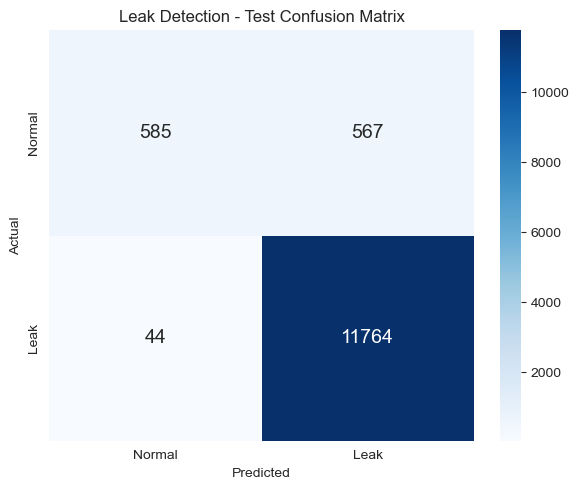

In [44]:
best_detection_model = detection_models[best_detection_name]
best_localization_model = localization_models[best_localization_name]

# ---- Detection ----
det_test_scores, det_test_pred = evaluate_detection(best_detection_model, X_test_det, y_det_test)

print(f"=== Final Leak Detection - {best_detection_name} (test) ===")
display(pd.Series(det_test_scores).round(4).to_frame("Test"))

cm = confusion_matrix(y_det_test, det_test_pred, labels=[0, 1])
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Normal", "Leak"], yticklabels=["Normal", "Leak"], annot_kws={"size": 14})
plt.title("Leak Detection - Test Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

In [45]:
# ---- Localization ----
loc_test_pred = best_localization_model.predict(X_test_loc)
loc_test_table, loc_test_overall = evaluate_localization(y_loc_test, loc_test_pred)

print(f"=== Final Leak Localization - {best_localization_name} (test) ===")
display(loc_test_table.round(4))
display(pd.Series(loc_test_overall).round(4).to_frame("Test"))

low_support = loc_test_table.loc[loc_test_table["Support"] < 20, "Link"].tolist()
if low_support:
    print("Links with fewer than 20 positive test rows (interpret with caution):", low_support)

=== Final Leak Localization - Random Forest (test) ===


,Link,Precision,Recall,F1-Score,Support
0,p31,0.7684,0.8872,0.8235,1152
1,p158,0.9962,0.9167,0.9548,1152
2,p183,1.0000,0.9796,0.9897,2592
3,p232,0.0000,0.0000,0.0000,0
4,p257,0.9206,1.0000,0.9587,11929
5,p369,0.8685,0.9514,0.9080,1152
6,p427,0.9540,0.9969,0.9749,11808
7,p461,0.8418,0.9792,0.9053,1152
8,p538,0.8309,0.9951,0.9056,617
9,p628,0.5620,0.5469,0.5543,1152


,Test
Macro F1 (links with support),0.9062
Macro Precision (links with support),0.8847
Macro Recall (links with support),0.9316
Micro F1,0.9371
Weighted F1,0.9376
Exact Match Accuracy,0.7170
Hamming Loss,0.0339


Links with fewer than 20 positive test rows (interpret with caution): ['p232']


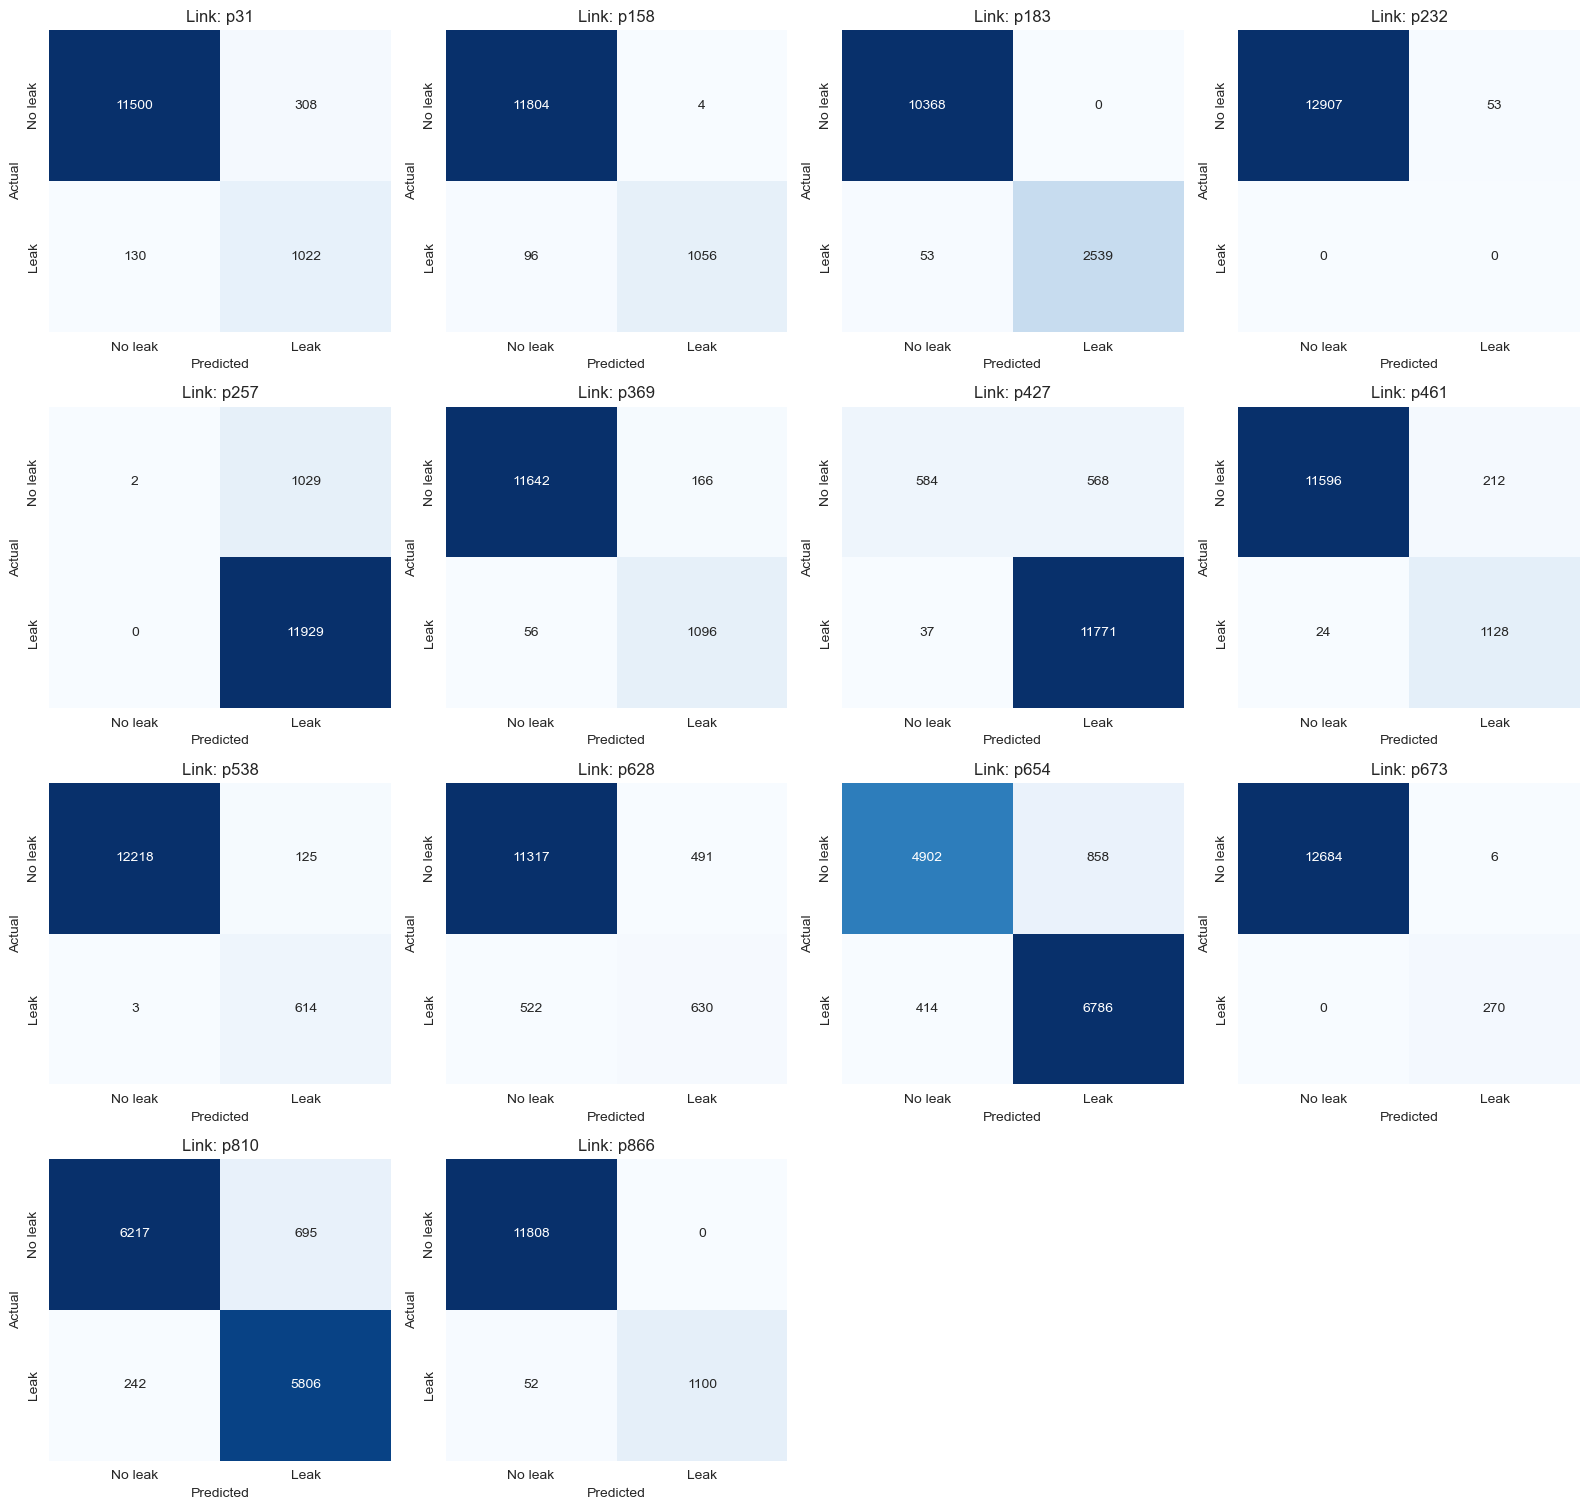

In [46]:
cms = multilabel_confusion_matrix(y_loc_test, loc_test_pred)

n_links = len(y_loc_test.columns)
n_cols = 4
n_rows = int(np.ceil(n_links / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3.8 * n_rows))
axes = axes.flatten()

for i, link in enumerate(y_loc_test.columns):
    sns.heatmap(cms[i], annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["No leak", "Leak"], yticklabels=["No leak", "Leak"], ax=axes[i])
    axes[i].set_title(f"Link: {link}")
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")

for ax in axes[n_links:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

## Part 3 - Step 7: Which Features Matter?

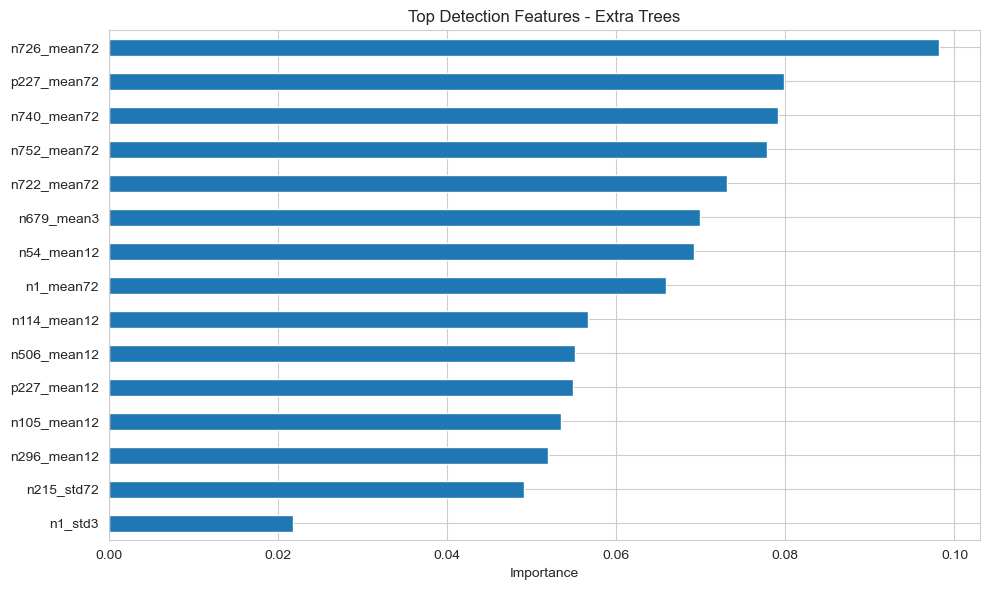

In [47]:
importances = pd.Series(best_detection_model.feature_importances_, index=det_feats).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
importances.head(15).sort_values().plot(kind="barh")
plt.title(f"Top Detection Features - {best_detection_name}")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## Part 3 - Step 8: Final Summary Table

In [48]:
final_summary = pd.DataFrame([
    {"Task": "Detection", "Model": best_detection_name,
     "Precision": det_test_scores["Normal Precision"], "Recall": det_test_scores["Normal Recall"],
     "F1-Score": det_test_scores["Normal F1"], "Note": "Normal = positive class"},
    {"Task": "Detection", "Model": best_detection_name,
     "Precision": det_test_scores["Leak Precision"], "Recall": det_test_scores["Leak Recall"],
     "F1-Score": det_test_scores["Leak F1"], "Note": "Leak = positive class"},
    {"Task": "Localization", "Model": best_localization_name,
     "Precision": loc_test_overall["Macro Precision (links with support)"],
     "Recall": loc_test_overall["Macro Recall (links with support)"],
     "F1-Score": loc_test_overall["Macro F1 (links with support)"], "Note": "Macro average"},
    {"Task": "Localization", "Model": best_localization_name,
     "Precision": np.nan, "Recall": np.nan,
     "F1-Score": loc_test_overall["Micro F1"], "Note": "Micro F1"},
])
display(final_summary.round(4))
print("Detection balanced accuracy:", round(det_test_scores["Balanced Accuracy"], 4),
      "| MCC:", round(det_test_scores["MCC"], 4))
print("Localization exact match:", round(loc_test_overall["Exact Match Accuracy"], 4),
      "| Hamming loss:", round(loc_test_overall["Hamming Loss"], 4))

,Task,Model,Precision,Recall,F1-Score,Note
0,Detection,Extra Trees,0.9300,0.5078,0.6569,Normal = positive class
1,Detection,Extra Trees,0.9540,0.9963,0.9747,Leak = positive class
2,Localization,Random Forest,0.8847,0.9316,0.9062,Macro average
3,Localization,Random Forest,NaN,NaN,0.9371,Micro F1


Detection balanced accuracy: 0.752 | MCC: 0.6676
Localization exact match: 0.717 | Hamming loss: 0.0339


### How to Read These Results

- The split is blocked in time with gaps, so the scores are **much less optimistic** than a random split, but they are still based on one year and one set of leak events.
- Each link has essentially one event. Localization performance therefore reflects recognising *known* leaks at other moments of the same event, not discovering unseen leaks.
- Compare the detection scores with the **time-only baseline** in section 3: the sensor-based model should clearly beat it.
- Links with few positive rows in validation or test have unstable scores (see the support column).

## Part 3 - Step 9: Saving the Models

In [49]:
model_artifacts = {
    "detection_model": best_detection_model,
    "detection_model_name": best_detection_name,
    "localization_model": best_localization_model,
    "localization_model_name": best_localization_name,
    "detection_features": det_feats,
    "localization_features": loc_feats,
    "link_names": y_loc_train.columns.tolist(),
    "config": d["config"],
}
joblib.dump(model_artifacts, ARTIFACT_DIR / "water_leakage_models.joblib")

loc_test_table.to_csv(ARTIFACT_DIR / "localization_test_results.csv", index=False)
final_summary.to_csv(ARTIFACT_DIR / "final_summary.csv", index=False)
print("Saved models and result tables to:", ARTIFACT_DIR)

Saved models and result tables to: c:\Users\dell\Desktop\Next Gen\artifacts


## Part 4 - Step 1: Loading Saved Models for Inference

In this section, we load the saved detection and localization models and their configuration.

These models will be used to make predictions on new, unseen sensor data without retraining.

In [50]:
import os
import joblib
import json

ARTIFACTS_DIR = ARTIFACT_DIR

print("Saved files:")
for file in os.listdir(ARTIFACTS_DIR):
    print(file)

Saved files:
final_summary.csv
localization_test_results.csv
prepared_data.joblib
water_leakage_models.joblib


In [51]:
models_path = os.path.join(
    ARTIFACTS_DIR,
    "water_leakage_models.joblib"
)

models = joblib.load(models_path)

print("Models loaded successfully!")

print(type(models))

if isinstance(models, dict):
    print("Available models:", models.keys())

Models loaded successfully!
<class 'dict'>
Available models: dict_keys(['detection_model', 'detection_model_name', 'localization_model', 'localization_model_name', 'detection_features', 'localization_features', 'link_names', 'config'])


## Part 4 - Step 2: Inspecting Loaded Models and Configuration

In this step, we inspect the loaded detection and localization models, their selected features, and the saved configuration to understand how they will be used for inference.

In [52]:
print("DETECTION MODEL:")
print(models['detection_model_name'])
print(models['detection_model'])

print("\nLOCALIZATION MODEL:")
print(models['localization_model_name'])
print(models['localization_model'])

print("\nDETECTION FEATURES:")
print(models['detection_features'])

print("\nLOCALIZATION FEATURES:")
print(models['localization_features'])

print("\nLINK NAMES:")
print(models['link_names'])

print("\nCONFIGURATION:")
print(models['config'])

DETECTION MODEL:
Extra Trees
ExtraTreesClassifier(class_weight='balanced', max_depth=15, min_samples_leaf=5,
                     n_estimators=200, n_jobs=-1, random_state=42)

LOCALIZATION MODEL:
Random Forest
MultiOutputClassifier(estimator=RandomForestClassifier(class_weight='balanced_subsample',
                                                       max_depth=15,
                                                       min_samples_leaf=5,
                                                       n_jobs=1,
                                                       random_state=42),
                      n_jobs=-1)

DETECTION FEATURES:
['n1_std3', 'n31_std3', 'n4_std3', 'n215_std12', 'n740_std3', 'n215_std72', 'n1_mean72', 'n215_std3', 'n722_mean72', 'n54_mean12', 'n506_mean12', 'n114_mean12', 'n752_mean72', 'p227_mean72', 'n679_mean3', 'p227_mean12', 'n740_mean72', 'n296_mean12', 'n105_mean12', 'n726_mean72']

LOCALIZATION FEATURES:
['PUMP_1_dev144', 'PUMP_1_mean12', 'PUMP_1_mean3', 'PUMP_1_

## Part 4 - Step 3: Inspecting Prepared Data for Inference

In this step, we load and inspect the prepared dataset to identify its structure, available features, and compatibility with the saved detection and localization models.

In [53]:
prepared_path = os.path.join(
    ARTIFACTS_DIR,
    "prepared_data.joblib"
)

prepared_data = joblib.load(prepared_path)

print("Prepared data loaded successfully!")
print("Data type:", type(prepared_data))

if isinstance(prepared_data, dict):
    print("\nAvailable keys:")
    for key, value in prepared_data.items():
        print(f"\n{key}:")
        print("Type:", type(value))

        if hasattr(value, "shape"):
            print("Shape:", value.shape)

        if hasattr(value, "columns"):
            print("Columns:", list(value.columns))

elif hasattr(prepared_data, "shape"):
    print("Shape:", prepared_data.shape)

    if hasattr(prepared_data, "columns"):
        print("Columns:", list(prepared_data.columns))

Prepared data loaded successfully!
Data type: <class 'dict'>

Available keys:

X_train:
Type: <class 'pandas.core.frame.DataFrame'>
Shape: (68976, 87)
Columns: ['PUMP_1_dev144', 'PUMP_1_mean12', 'PUMP_1_mean3', 'PUMP_1_mean72', 'n105_mean12', 'n105_mean72', 'n114_mean12', 'n163_mean12', 'n163_mean72', 'n188_mean72', 'n1_mean72', 'n1_std3', 'n215', 'n215_dev144', 'n215_mean12', 'n215_mean3', 'n215_mean72', 'n215_std12', 'n215_std3', 'n215_std72', 'n229', 'n229_mean12', 'n229_mean3', 'n229_mean72', 'n288_mean12', 'n288_mean72', 'n288_std3', 'n296', 'n296_mean12', 'n296_mean3', 'n296_mean72', 'n31_mean72', 'n31_std3', 'n31_std72', 'n332_mean12', 'n332_mean72', 'n410_mean12', 'n410_mean3', 'n410_mean72', 'n429_mean3', 'n429_mean72', 'n429_std3', 'n469_mean72', 'n495_mean72', 'n495_std3', 'n4_mean72', 'n4_std3', 'n506_mean12', 'n506_mean3', 'n506_mean72', 'n506_std3', 'n516_mean12', 'n516_mean72', 'n549_mean72', 'n54_mean12', 'n54_mean3', 'n54_std3', 'n613_mean12', 'n636_std3', 'n644', 'n64

## Part 4 - Step 4: Testing Saved Models on the Test Set

In this step, we use the previously saved detection and localization models to generate predictions on the test dataset.

The predictions are compared with the actual labels to evaluate the performance of both models without retraining.

In [54]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    hamming_loss
)
import pandas as pd

# Prepare test features
X_test = prepared_data['X_test']

det_features = models['detection_features']
loc_features = models['localization_features']

# Check feature availability
assert set(det_features).issubset(X_test.columns)
assert set(loc_features).issubset(X_test.columns)

# Detection predictions
detection_predictions = models['detection_model'].predict(
    X_test[det_features]
)

# Localization predictions
localization_predictions = models['localization_model'].predict(
    X_test[loc_features]
)

# Actual labels
y_det_test = prepared_data['y_det_test']
y_loc_test = prepared_data['y_loc_test']

# Detection evaluation
print("===== DETECTION RESULTS =====")
print("Accuracy:", accuracy_score(y_det_test, detection_predictions))
print("Precision:", precision_score(y_det_test, detection_predictions, pos_label=0, zero_division=0))
print("Recall:", recall_score(y_det_test, detection_predictions, pos_label=0, zero_division=0))
print("F1 Score:", f1_score(y_det_test, detection_predictions, pos_label=0, zero_division=0))

# Localization evaluation
localization_predictions = pd.DataFrame(
    localization_predictions,
    columns=models['link_names'],
    index=y_loc_test.index
)

print("\n===== LOCALIZATION RESULTS =====")
print("Exact Match Accuracy:",
      accuracy_score(y_loc_test, localization_predictions))

print("Hamming Loss:",
      hamming_loss(y_loc_test, localization_predictions))

# Per-link evaluation
localization_results = []

for link in models['link_names']:
    localization_results.append({
        "Link": link,
        "Precision": precision_score(
            y_loc_test[link],
            localization_predictions[link],
            zero_division=0
        ),
        "Recall": recall_score(
            y_loc_test[link],
            localization_predictions[link],
            zero_division=0
        ),
        "F1 Score": f1_score(
            y_loc_test[link],
            localization_predictions[link],
            zero_division=0
        )
    })

localization_results_df = pd.DataFrame(localization_results)

print("\n===== PERFORMANCE PER LINK =====")
display(localization_results_df)

===== DETECTION RESULTS =====
Accuracy: 0.952854938271605
Precision: 0.9300476947535771
Recall: 0.5078125
F1 Score: 0.656934306569343

===== LOCALIZATION RESULTS =====
Exact Match Accuracy: 0.7169753086419753
Hamming Loss: 0.033862433862433865

===== PERFORMANCE PER LINK =====


,Link,Precision,Recall,F1 Score
0,p31,0.768421,0.887153,0.823529
1,p158,0.996226,0.916667,0.954792
2,p183,1.000000,0.979552,0.989671
3,p232,0.000000,0.000000,0.000000
4,p257,0.920590,1.000000,0.958653
5,p369,0.868463,0.951389,0.908036
6,p427,0.953967,0.996867,0.974945
7,p461,0.841791,0.979167,0.905297
8,p538,0.830853,0.995138,0.905605
9,p628,0.561998,0.546875,0.554333


## Part 4 - Step 5: Investigating Localization Predictions

In this section, we inspect the actual and predicted positive cases for each link.

This helps identify links with poor localization performance and understand whether the issue is related to the test data or model predictions.

In [55]:
localization_diagnostics = []

for link in models['link_names']:
    actual_positive = int(y_loc_test[link].sum())
    predicted_positive = int(localization_predictions[link].sum())

    localization_diagnostics.append({
        "Link": link,
        "Actual Positive Cases": actual_positive,
        "Predicted Positive Cases": predicted_positive
    })

localization_diagnostics_df = pd.DataFrame(
    localization_diagnostics
)

display(localization_diagnostics_df)

,Link,Actual Positive Cases,Predicted Positive Cases
0,p31,1152,1330
1,p158,1152,1060
2,p183,2592,2539
3,p232,0,53
4,p257,11929,12958
5,p369,1152,1262
6,p427,11808,12339
7,p461,1152,1340
8,p538,617,739
9,p628,1152,1121


In [56]:
from pathlib import Path


print("Folder exists:", DATA_DIR.exists())

if DATA_DIR.exists():
    print("\nFiles found:")
    for file in DATA_DIR.iterdir():
        print(file.name)
else:
    print("Dataset folder was not found.")

Folder exists: True

Files found:
2018_Leakages.csv
2018_SCADA_Flows.csv
2018_SCADA_Pressures.csv
dataset_configuration.yaml
L-TOWN.inp
README.txt


## Inspecting the Raw Dataset

In this stage, we inspect the original SCADA pressure, flow, and leakage
datasets to understand their structure, sensor columns, and data format
before preparing the application input pipeline.

In [57]:
import pandas as pd
from pathlib import Path


files = {
    "Pressures": "2018_SCADA_Pressures.csv",
    "Flows": "2018_SCADA_Flows.csv",
    "Leakages": "2018_Leakages.csv"
}

for name, filename in files.items():
    print("\n" + "=" * 60)
    print(f"{name} DATASET")
    print("=" * 60)

    df = pd.read_csv(DATA_DIR / filename, nrows=5)

    print("Columns:")
    print(df.columns.tolist())

    print("\nFirst 5 rows:")
    display(df)


Pressures DATASET
Columns:
['Timestamp;n1;n4;n31;n54;n105;n114;n163;n188;n215;n229;n288;n296;n332;n342;n410;n415;n429;n458;n469;n495;n506;n516;n519;n549;n613;n636;n644;n679;n722;n726;n740;n752;n769']

First 5 rows:


,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,Timestamp;n1;n4;n31;n54;n105;n114;n163;n188;n215;n229;n288;n296;n332;n342;n410;n415;n429;n458;n469;n495;n506;n516;n519;n549;n613;n636;n644;n679;n722;n726;n740;n752;n769
2018-01-01 00:00:00;28,92;33,87;37,13;37,13;50,52;53,99;52,56;55,32;39,09;52,53;52,81;42,45;56,43;46,75;31,07;45,62;36,79;43,52;47,54;51,7;53,54;54,85;47,58;54,8;56,16;45,53;47,62;47,33;46,14;47,12;43,81;49,17;48,5.0
2018-01-01 00:05:00;28,94;33,89;37,16;37,23;50,6;54,09;52,67;55,42;39,1;52,67;52,88;42,48;56,52;46,85;31,18;45,71;36,9;43,62;47,62;51,75;53,63;54,96;47,67;54,9;56,26;45,61;47,71;47,39;46,19;47,17;43,83;49,22;48,54.0
2018-01-01 00:10:00;28,96;33,91;37,18;37,21;50,57;54,05;52,64;55,39;39,09;52,64;52,89;42,5;56,49;46,84;31,16;45,68;36,88;43,6;47,59;51,73;53,6;54,93;47,65;54,87;56,24;45,61;47,71;47,41;46,2;47,19;43,84;49,24;48,56.0
2018-01-01 00:15:00;28,98;33,93;37,19;37,27;50,6;54,08;52,7;55,45;39,09;52,69;52,92;42,51;56,53;46,89;31,22;45,74;36,94;43,65;47,62;51,76;53,63;54,97;47,7;54,92;56,3;45,65;47,75;47,43;46,21;47,21;43,84;49,26;48,57.0
2018-01-01 00:20:00;28,98;33,93;37,19;37,14;50,53;54;52,57;55,32;39,09;52,56;52,82;42,45;56,44;46,76;31,09;45,63;36,81;43,52;47,55;51,7;53,55;54,86;47,59;54,8;56,17;45,54;47,64;47,34;46,15;47,13;43,81;49,17;48,5,NaN



Flows DATASET
Columns:
['Timestamp;p227;p235;PUMP_1']

First 5 rows:


,,,Timestamp;p227;p235;PUMP_1
2018-01-01 00:00:00;77,77;83,93;44,4
2018-01-01 00:05:00;72,51;76,34;44,6
2018-01-01 00:10:00;71,54;78,68;44,6
2018-01-01 00:15:00;69,85;75,5;44,7
2018-01-01 00:20:00;77,12;82,99;44,3



Leakages DATASET
Columns:
['Timestamp;p31;p158;p183;p232;p257;p369;p427;p461;p538;p628;p654;p673;p810;p866']

First 5 rows:


,Timestamp;p31;p158;p183;p232;p257;p369;p427;p461;p538;p628;p654;p673;p810;p866
0,2018-01-01 00:00:00;0;0;0;0;0;0;0;0;0;0;0;0;0;0
1,2018-01-01 00:05:00;0;0;0;0;0;0;0;0;0;0;0;0;0;0
2,2018-01-01 00:10:00;0;0;0;0;0;0;0;0;0;0;0;0;0;0
3,2018-01-01 00:15:00;0;0;0;0;0;0;0;0;0;0;0;0;0;0
4,2018-01-01 00:20:00;0;0;0;0;0;0;0;0;0;0;0;0;0;0


## Loading the Raw Datasets

The original CSV files use semicolons (;) as delimiters.
We load them using the correct separator and inspect their dimensions,
column names, data types, and missing values.

In [58]:
import pandas as pd
from pathlib import Path


pressures_df = pd.read_csv(DATA_DIR / "2018_SCADA_Pressures.csv", sep=";", decimal=",")
flows_df = pd.read_csv(DATA_DIR / "2018_SCADA_Flows.csv", sep=";", decimal=",")
leakages_df = pd.read_csv(DATA_DIR / "2018_Leakages.csv", sep=";", decimal=",")

datasets = {
    "Pressures": pressures_df,
    "Flows": flows_df,
    "Leakages": leakages_df
}

for name, df in datasets.items():
    print("\n" + "=" * 50)
    print(name)
    print("=" * 50)

    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())

    print("\nData Types:")
    print(df.dtypes)

    print("\nMissing Values:")
    print(df.isnull().sum().sum())

    print("\nFirst 3 Rows:")
    display(df.head(3))


Pressures
Shape: (105120, 34)
Columns: ['Timestamp', 'n1', 'n4', 'n31', 'n54', 'n105', 'n114', 'n163', 'n188', 'n215', 'n229', 'n288', 'n296', 'n332', 'n342', 'n410', 'n415', 'n429', 'n458', 'n469', 'n495', 'n506', 'n516', 'n519', 'n549', 'n613', 'n636', 'n644', 'n679', 'n722', 'n726', 'n740', 'n752', 'n769']

Data Types:
Timestamp     object
n1           float64
n4           float64
n31          float64
n54          float64
n105         float64
n114         float64
n163         float64
n188         float64
n215         float64
n229         float64
n288         float64
n296         float64
n332         float64
n342         float64
n410         float64
n415         float64
n429         float64
n458         float64
n469         float64
n495         float64
n506         float64
n516         float64
n519         float64
n549         float64
n613         float64
n636         float64
n644         float64
n679         float64
n722         float64
n726         float64
n740         float64
n75

,Timestamp,n1,n4,n31,n54,n105,n114,n163,n188,n215,...,n549,n613,n636,n644,n679,n722,n726,n740,n752,n769
0,2018-01-01 00:00:00,28.92,33.87,37.13,37.13,50.52,53.99,52.56,55.32,39.09,...,54.80,56.16,45.53,47.62,47.33,46.14,47.12,43.81,49.17,48.50
1,2018-01-01 00:05:00,28.94,33.89,37.16,37.23,50.60,54.09,52.67,55.42,39.10,...,54.90,56.26,45.61,47.71,47.39,46.19,47.17,43.83,49.22,48.54
2,2018-01-01 00:10:00,28.96,33.91,37.18,37.21,50.57,54.05,52.64,55.39,39.09,...,54.87,56.24,45.61,47.71,47.41,46.20,47.19,43.84,49.24,48.56



Flows
Shape: (105120, 4)
Columns: ['Timestamp', 'p227', 'p235', 'PUMP_1']

Data Types:
Timestamp     object
p227         float64
p235         float64
PUMP_1       float64
dtype: object

Missing Values:
0

First 3 Rows:


,Timestamp,p227,p235,PUMP_1
0,2018-01-01 00:00:00,77.77,83.93,44.04
1,2018-01-01 00:05:00,72.51,76.34,44.06
2,2018-01-01 00:10:00,71.54,78.68,44.06



Leakages
Shape: (105120, 15)
Columns: ['Timestamp', 'p31', 'p158', 'p183', 'p232', 'p257', 'p369', 'p427', 'p461', 'p538', 'p628', 'p654', 'p673', 'p810', 'p866']

Data Types:
Timestamp     object
p31          float64
p158         float64
p183         float64
p232         float64
p257         float64
p369         float64
p427         float64
p461         float64
p538         float64
p628         float64
p654         float64
p673         float64
p810         float64
p866         float64
dtype: object

Missing Values:
0

First 3 Rows:


,Timestamp,p31,p158,p183,p232,p257,p369,p427,p461,p538,p628,p654,p673,p810,p866
0,2018-01-01 00:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2018-01-01 00:05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2018-01-01 00:10:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
